# Hebrew crowd-recital: exploratory data analysis

Executed analysis of the original session corpus, not the derived Whisper training set.
Read [EDA_PLAN.md](EDA_PLAN.md) for the prespecified workflow, screening rules, and sources.
The supplied HebSpoof PDF informs downstream questions; it does not authorize synthesis or model training.

**Interpretation:** `biological_sex` is the source label, not gender identity. Birth year does not provide age at recording. `quality_score` is alignment confidence, not acoustic quality. All flags are review candidates, never automatic exclusions. Independent sampling units are speakers; recordings and segments repeat speakers.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, re, unicodedata, platform, importlib.metadata, time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Audio, Markdown
import av
SEED = 20261115
rng = np.random.default_rng(SEED)
ROOT = Path.cwd()
if not (ROOT / 'EDA_PLAN.md').exists():
    raise RuntimeError('Run this notebook with the project directory as working directory.')
OUT = ROOT / 'eda_outputs'; OUT.mkdir(exist_ok=True)
FIG = OUT / 'figures'; FIG.mkdir(exist_ok=True)
SNAPSHOT = Path(os.environ.get('CROWD_RECITAL_PATH', str(Path.home()/'.cache/huggingface/hub/datasets--ivrit-ai--crowd-recital/snapshots/34d93a876ae075a1a7904e7ec2c54d2af1c9d4d7')))
assert (SNAPSHOT/'manifest.csv').exists(), f'Missing manifest: {SNAPSHOT}'
run = {'dataset':'ivrit-ai/crowd-recital','revision':SNAPSHOT.name,'input_path':str(SNAPSHOT),
       'seed':SEED,'analysis_reference_year':2026,'started_utc':pd.Timestamp.now(tz='UTC').isoformat(),
       'python':sys.version,'platform':platform.platform(),
       'versions':{x:importlib.metadata.version(x) for x in ['pandas','numpy','matplotlib','seaborn','av','nbformat','nbclient']}}
(OUT/'run_provenance.json').write_text(json.dumps(run,indent=2),encoding='utf-8')
pd.set_option('display.max_columns',30)
sns.set_theme(style='whitegrid',context='notebook')
plt.rcParams.update({'figure.figsize':(11,5),'figure.dpi':110})
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG/f'{name}.png',dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def export(df,name):
    df.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')
def digest(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()
manifest=pd.read_csv(SNAPSHOT/'manifest.csv')
display(manifest.head()); print('Manifest shape:',manifest.shape)


,source_type,source_id,source_entry_id,session_id,session_duration,user_id,document_language,document_title,document_source_type,year_of_birth,biological_sex,quality_score,min_segment_quality_score,avg_words_per_segment,avg_segment_duration,avg_words_per_minute,segments_count,words_count
0,crowd_recital,recital,xLg5pCP5t36nm3FIGk3MA,xLg5pCP5t36nm3FIGk3MA,59.141000,69ab8aa7-1b54-4f7e-9701-d988da19cb6c,he,מדריך הטרמפיסט לגלקסיה (ספר),wiki-article,1981.0,male,0.9786,0.0482,8.6316,2.6121,166.3820,19,164
1,crowd_recital,recital,ikV7P7s5IFqdXRVbWYZ5E,ikV7P7s5IFqdXRVbWYZ5E,9.400000,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,he,מדריך הטרמפיסט לגלקסיה (ספר),wiki-article,NaN,unspecified,0.9735,0.9666,10.0000,3.5500,127.6596,2,20
2,crowd_recital,recital,0xdnEvpLZFBFneDIIsCFP,0xdnEvpLZFBFneDIIsCFP,70.840000,69ab8aa7-1b54-4f7e-9701-d988da19cb6c,he,צביקה פיק,wiki-article,1981.0,male,0.7739,0.0000,5.5833,2.0150,113.4952,24,134
3,crowd_recital,recital,HTZhS_9Rop8JRmzEB6btX,HTZhS_9Rop8JRmzEB6btX,130.101000,69ab8aa7-1b54-4f7e-9701-d988da19cb6c,he,צביקה פיק,wiki-article,1981.0,male,0.9345,0.0000,6.0000,2.1776,113.4503,41,246
4,crowd_recital,recital,8bVHd36C8Z7F31VaZmp3L,8bVHd36C8Z7F31VaZmp3L,11.458667,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,he,מַקְהֵלַת נוֹגְנִים / חיים נחמן ביאליק,file-upload,NaN,unspecified,0.0145,0.0145,4.0000,4.8600,20.9448,1,4


Manifest shape: (2398, 18)


## 1. Inventory, schema, and integrity
Inventory hashes cover the downloaded files, including original audio. Presence checks are separate from successful parsing or decoding. Manifest/JSON disagreement is retained for investigation.

In [2]:
files=sorted(p for p in SNAPSHOT.rglob('*') if p.is_file() and '.cache' not in p.relative_to(SNAPSHOT).parts)
assert len(files)>=len(manifest)*4+1, 'Incomplete input inventory'
def inventory_one(p): return {'path':p.relative_to(SNAPSHOT).as_posix(),'bytes':p.stat().st_size,'sha256':digest(p)}
with ThreadPoolExecutor(max_workers=4) as pool: inventory=pd.DataFrame(pool.map(inventory_one,files))
export(inventory,'file_inventory')
session_dirs=sorted(p for p in SNAPSHOT.iterdir() if p.is_dir() and not p.name.startswith('.'))
expected=['audio.mka','metadata.json','transcript.aligned.json','transcript.vtt']
presence=pd.DataFrame([{'session_id':p.name,**{x:(p/x).is_file() for x in expected}} for p in session_dirs])
export(presence,'companion_file_presence')
dictionary=pd.DataFrame([{'field':c,'dtype':str(manifest[c].dtype),'missing':int(manifest[c].isna().sum()),'missing_pct':100*manifest[c].isna().mean(),'unique_nonmissing':manifest[c].nunique()} for c in manifest])
definitions={
 'source_type':('category','Source collection type'), 'source_id':('identifier','Source collection identifier'),
 'source_entry_id':('identifier','Source recording identifier'), 'session_id':('identifier','Recording session identifier'),
 'session_duration':('seconds','Reported complete recording duration'), 'user_id':('identifier','Opaque recorder identifier; speaker grouping proxy'),
 'document_language':('language code','Source document language'), 'document_title':('text','Source document title'),
 'document_source_type':('category','Source document origin'), 'year_of_birth':('calendar year','Reported birth year, if supplied'),
 'biological_sex':('source category','Reported source sex label; not gender identity'),
 'quality_score':('0-1','Provider text/audio alignment quality; not acoustic quality'),
 'min_segment_quality_score':('0-1','Minimum provider segment alignment score'),
 'avg_words_per_segment':('words/segment','Reported average aligned words per segment'),
 'avg_segment_duration':('seconds','Reported average aligned segment duration'),
 'avg_words_per_minute':('words/minute','Reported recording word rate'),
 'segments_count':('count','Reported aligned segment count'), 'words_count':('count','Reported word count')}
dictionary['units']=dictionary.field.map(lambda c:definitions.get(c,('unknown','Undocumented'))[0])
dictionary['meaning']=dictionary.field.map(lambda c:definitions.get(c,('unknown','Undocumented'))[1])
export(dictionary,'data_dictionary'); display(dictionary)
integrity=[]; metadata={}; aligned={}; segments=[]; words=[]; qsegments=[]; textrows=[]; discrepancies=[]
def issue(sid,check,detail): integrity.append({'session_id':sid,'check':check,'detail':str(detail)})
def norm(text):
    text=unicodedata.normalize('NFKC',str(text))
    text=''.join(c for c in text if not unicodedata.category(c).startswith(('M','P')))
    return ' '.join(text.casefold().split())
manifest_ids=set(manifest.session_id)
for p in session_dirs:
    sid=p.name
    if sid not in manifest_ids: issue(sid,'orphan_directory','not in manifest')
    for f in expected:
        if not (p/f).exists(): issue(sid,'missing_companion',f)
    try:
        m=json.loads((p/'metadata.json').read_text(encoding='utf-8')); metadata[sid]=m
        a=json.loads((p/'transcript.aligned.json').read_text(encoding='utf-8')); aligned[sid]=a
    except Exception as e:
        issue(sid,'json_parse_error',e); continue
    duration=float(m.get('session_duration',np.nan)); ss=a.get('segments',[])
    if len(ss)!=m.get('segments_count'): issue(sid,'segment_count_mismatch',f"{len(ss)} vs {m.get('segments_count')}")
    if m.get('session_id')!=sid: issue(sid,'directory_metadata_id_mismatch',m.get('session_id'))
    if a.get('language') not in ('he',None): issue(sid,'aligned_language',a.get('language'))
    previous_end=-np.inf
    for i,s in enumerate(ss):
        start=float(s['start']); end=float(s['end']); text=s.get('text',''); sw=s.get('words',[])
        bad=not (np.isfinite(start) and np.isfinite(end) and start>=0 and end>start and end<=duration+0.1)
        overlap=start<previous_end-0.02
        if bad: issue(sid,'segment_timestamp_invalid',i)
        if overlap: issue(sid,'segment_overlap',i)
        segments.append({'session_id':sid,'segment_index':i,'start':start,'end':end,'duration_s':end-start,'gap_before_s':max(0,start-previous_end) if i else start,'text':text,'normalized_text':norm(text),'word_count':len(sw),'timestamp_invalid':bad,'overlap':overlap})
        previous_end=end
        wprev=-np.inf
        for j,w in enumerate(sw):
            ws=float(w['start']); we=float(w['end']); invalid=not(np.isfinite(ws) and np.isfinite(we) and ws>=start-0.1 and we>=ws and we<=end+0.1)
            if invalid: issue(sid,'word_timestamp_invalid',f'{i}:{j}')
            words.append({'session_id':sid,'segment_index':i,'word_index':j,'word':w.get('word',''),'start':ws,'end':we,'duration_s':we-ws,'probability':w.get('probability'), 'timestamp_invalid':invalid,'overlap':ws<wprev-0.02})
            wprev=we
    for i,q in enumerate(m.get('per_segment_quality_scores',[])):
        qsegments.append({'session_id':sid,'quality_index':i,**q})
    text=a.get('text',''); vtt=(p/'transcript.vtt').read_text(encoding='utf-8-sig') if (p/'transcript.vtt').exists() else ''
    lines=[]; in_cue=False
    for line in vtt.splitlines():
        line=line.strip()
        if '-->' in line: in_cue=True; continue
        if not line: in_cue=False; continue
        if in_cue: lines.append(re.sub(r'<[^>]*>','',line))
    vtext=' '.join(lines)
    letters=[c for c in text if c.isalpha()]
    textrows.append({'session_id':sid,'text':text,'normalized_text':norm(text),'char_count':len(text),'whitespace_words':len(text.split()),'hebrew_letter_fraction':sum('\u05d0'<=c<='\u05ea' for c in letters)/len(letters) if letters else np.nan,'has_latin':bool(re.search('[A-Za-z]',text)),'has_digits':bool(re.search('[0-9]',text)),'has_niqqud':bool(re.search('[\u0591-\u05c7]',text)),'has_question':('?' in text),'vtt_normalized_match':norm(vtext)==norm(text),'empty_text':not bool(text.strip())})
for sid in manifest_ids-set(p.name for p in session_dirs): issue(sid,'missing_session_directory','')
for _,r in manifest.iterrows():
    for field in ['session_id','source_entry_id','user_id','source_type','source_id']:
        if pd.isna(r[field]): issue(r.session_id,'missing_critical_field',field)
    for field in ['session_duration','segments_count','words_count','avg_segment_duration','avg_words_per_segment','avg_words_per_minute']:
        if pd.notna(r[field]) and (not np.isfinite(r[field]) or r[field]<0): issue(r.session_id,'invalid_manifest_numeric',field)
    for field in ['quality_score','min_segment_quality_score']:
        if pd.notna(r[field]) and not 0<=r[field]<=1: issue(r.session_id,'invalid_probability',field)
for _,r in manifest.iterrows():
    sid=r.session_id
    if sid not in metadata: continue
    for c in manifest:
        if c not in metadata[sid]: continue
        a=r[c]; b=metadata[sid][c]
        equal=(pd.isna(a) and b is None) or (isinstance(a,(float,int)) and isinstance(b,(float,int)) and np.isclose(a,b,rtol=1e-4,atol=1e-4)) or str(a)==str(b)
        if not equal: discrepancies.append({'session_id':sid,'field':c,'manifest':a,'metadata':b})
for sid in manifest.loc[manifest.session_id.duplicated(False),'session_id']: issue(sid,'duplicate_manifest_id','')
seg=pd.DataFrame(segments); word=pd.DataFrame(words); qs=pd.DataFrame(qsegments); textdf=pd.DataFrame(textrows)
for _,r in qs.iterrows():
    d=metadata.get(r.session_id,{}).get('session_duration',np.nan)
    if not (0<=r.start<r.end<=d+.1): issue(r.session_id,'quality_segment_timestamp_invalid',r.quality_index)
    if pd.notna(r.probability) and not 0<=r.probability<=1: issue(r.session_id,'quality_probability_invalid',r.quality_index)
for _,r in word.loc[word.probability.notna() & ~word.probability.between(0,1)].iterrows(): issue(r.session_id,'word_probability_invalid',r.word_index)
metadata_schema=Counter(key for m in metadata.values() for key in m)
export(pd.DataFrame([{'field':k,'sessions_present':v,'sessions_missing':len(metadata)-v} for k,v in metadata_schema.items()]),'metadata_field_coverage')
checks=pd.DataFrame(integrity,columns=['session_id','check','detail'])
diff=pd.DataFrame(discrepancies,columns=['session_id','field','manifest','metadata'])
export(checks,'integrity_issues'); export(diff,'manifest_metadata_disagreements')
export(seg,'segments'); export(word,'words'); export(qs,'segment_quality'); export(textdf,'transcript_features')
display(checks.groupby('check').size().rename('occurrences').to_frame()); print('Manifest/metadata disagreements:',len(diff)); display(presence[expected].sum())


,field,dtype,missing,missing_pct,unique_nonmissing,units,meaning
0,source_type,object,0,0.000000,1,category,Source collection type
1,source_id,object,0,0.000000,1,identifier,Source collection identifier
2,source_entry_id,object,0,0.000000,2398,identifier,Source recording identifier
3,session_id,object,0,0.000000,2398,identifier,Recording session identifier
4,session_duration,float64,0,0.000000,2239,seconds,Reported complete recording duration
5,user_id,object,0,0.000000,85,identifier,Opaque recorder identifier; speaker grouping p...
6,document_language,object,0,0.000000,1,language code,Source document language
7,document_title,object,0,0.000000,449,text,Source document title
8,document_source_type,object,0,0.000000,3,category,Source document origin
9,year_of_birth,float64,349,14.553795,36,calendar year,"Reported birth year, if supplied"


,occurrences
check,
quality_segment_timestamp_invalid,1428
segment_timestamp_invalid,1428


Manifest/metadata disagreements: 0


audio.mka                  2398
metadata.json              2398
transcript.aligned.json    2398
transcript.vtt             2398
dtype: int64

## 2. Complete feature distributions
Percentages retain missing values. Identifier counts describe repetition, not meaningful semantic categories. Histograms include all numeric fields; derived acoustic and transcript features follow below.

,field,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,session_duration,2398.0,75.773869,114.044189,0.090667,1.876053,3.306533,9.404667,37.914667,95.271333,265.722044,545.176800,1459.8000
1,year_of_birth,2049.0,1773.922889,613.891967,0.000000,0.000000,0.000000,1978.000000,1984.000000,1993.000000,1999.000000,2009.000000,2009.0000
2,quality_score,2398.0,0.892779,0.180124,0.000000,0.000000,0.651940,0.881300,0.953900,0.978000,0.993200,0.997103,0.9995
3,min_segment_quality_score,2398.0,0.596145,0.307487,0.000000,0.000000,0.000000,0.407575,0.663350,0.845800,0.986300,0.996400,0.9995
4,avg_words_per_segment,2398.0,6.146556,1.707823,1.000000,2.000000,3.241660,5.300000,6.130400,7.000000,9.000000,11.000000,14.0000
5,avg_segment_duration,2398.0,2.609129,0.926756,0.000000,0.000000,1.078560,2.155000,2.558550,3.020000,4.200300,5.362400,7.5200
6,avg_words_per_minute,2398.0,107.858986,148.426212,0.531200,35.474300,66.332700,92.579025,105.468950,118.149400,140.041330,157.367164,7279.4118
7,segments_count,2398.0,22.569641,34.581628,1.000000,1.000000,1.000000,3.000000,10.000000,29.000000,81.000000,158.000000,452.0000
8,words_count,2398.0,135.592994,208.269526,1.000000,2.000000,4.000000,16.000000,66.000000,170.000000,484.150000,969.420000,2865.0000


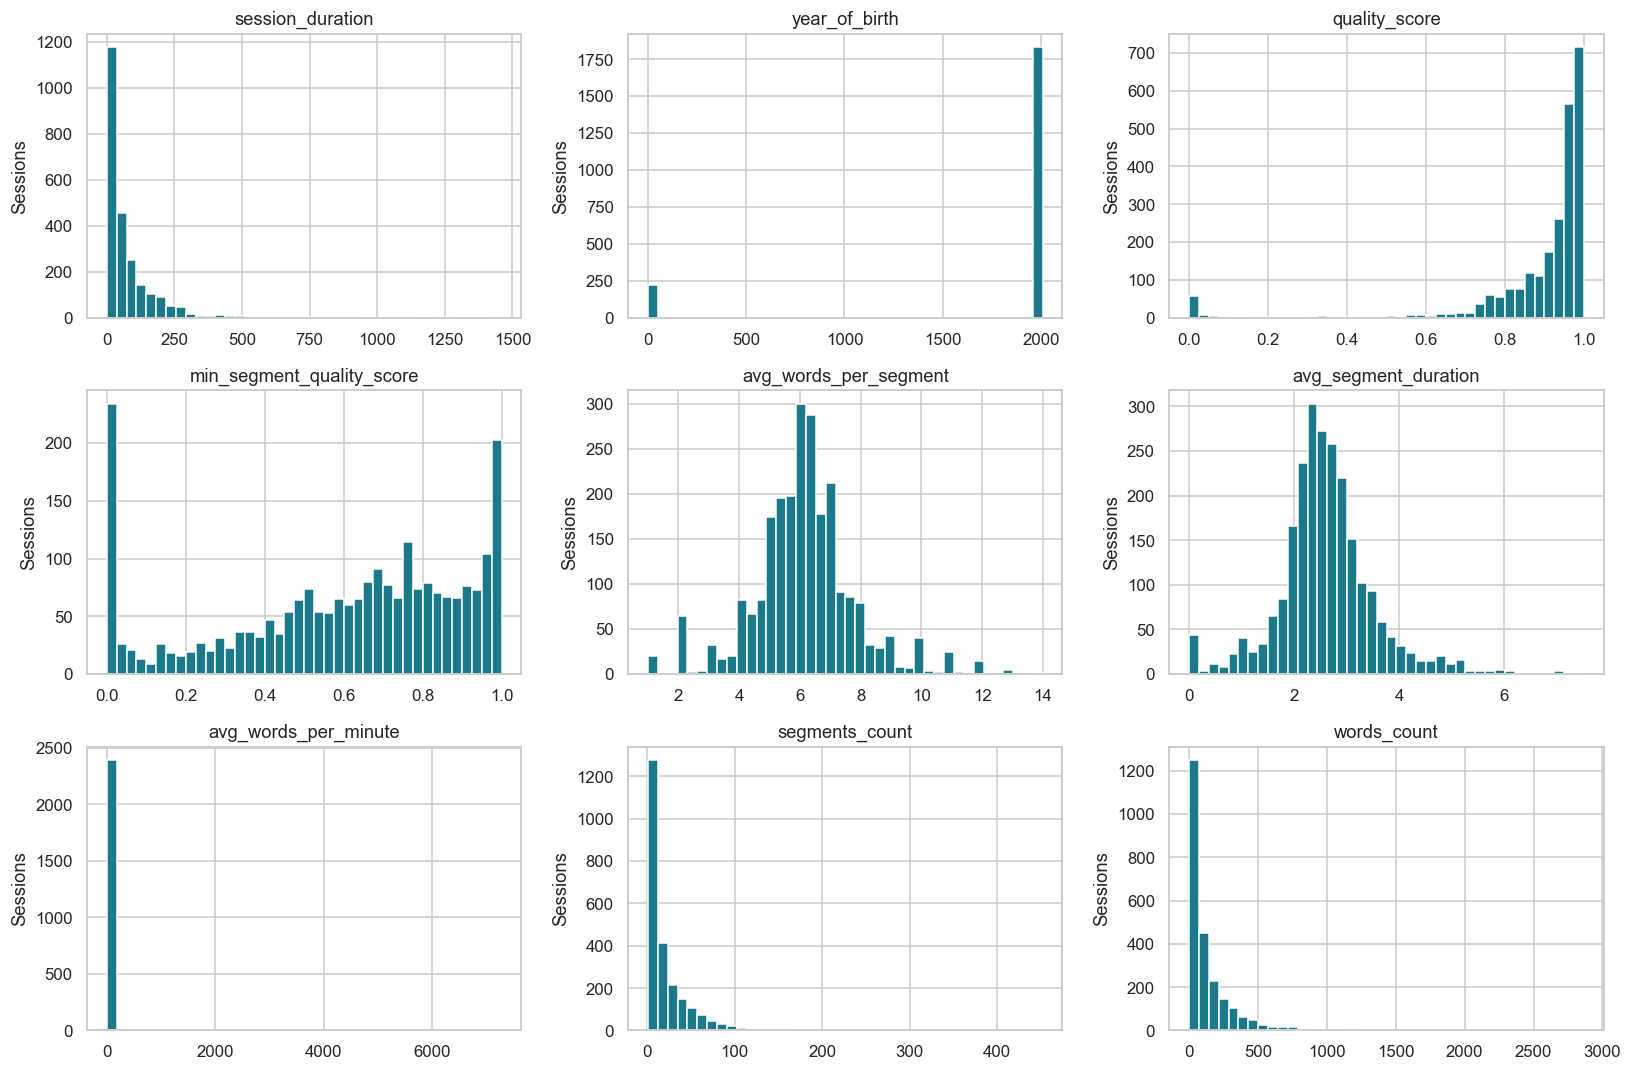

,value
sessions,2398.000000
speakers,85.000000
hours,50.473816
manifest_words,325152.000000
manifest_segments,54122.000000
aligned_words,325152.000000
aligned_segments,54122.000000
documents,449.000000
inventory_files,9597.000000
inventory_gb,3.086315


,field,value,sessions,pct
0,source_type,crowd_recital,2398,100.0


,field,value,sessions,pct
1,source_id,recital,2398,100.0


,field,value,sessions,pct
4883,document_language,he,2398,100.0


,field,value,sessions,pct
5333,document_source_type,wiki-article,2361,98.457048
5334,document_source_type,plain-text,24,1.000834
5335,document_source_type,file-upload,13,0.542118


,field,value,sessions,pct
5336,biological_sex,male,1739,72.518766
5337,biological_sex,female,481,20.058382
5338,biological_sex,<missing>,131,5.462886
5339,biological_sex,unspecified,47,1.959967


In [3]:
df=manifest.merge(textdf,on='session_id',how='left',validate='one_to_one')
numeric=manifest.select_dtypes(include='number').columns.tolist()
summary=manifest[numeric].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T.reset_index(names='field')
export(summary,'numeric_summary'); display(summary)
cats=[]
for c in manifest.select_dtypes(exclude='number'):
    counts=manifest[c].fillna('<missing>').value_counts(dropna=False)
    cats.extend({'field':c,'value':v,'sessions':n,'pct':100*n/len(manifest)} for v,n in counts.items())
categoricals=pd.DataFrame(cats); export(categoricals,'categorical_distributions')
fig,axes=plt.subplots(int(np.ceil(len(numeric)/3)),3,figsize=(15,3.3*int(np.ceil(len(numeric)/3))))
for ax,c in zip(axes.flat,numeric):
    ax.hist(manifest[c].dropna(),bins=40,color='#197a8c'); ax.set(title=c,ylabel='Sessions')
for ax in axes.flat[len(numeric):]: ax.set_visible(False)
savefig('manifest_numeric_distributions')
overview={'sessions':len(df),'speakers':int(df.user_id.nunique()),'hours':float(df.session_duration.sum()/3600),'manifest_words':int(df.words_count.sum()),'manifest_segments':int(df.segments_count.sum()),'aligned_words':len(word),'aligned_segments':len(seg),'documents':int(df.document_title.nunique()),'inventory_files':len(inventory),'inventory_gb':float(inventory.bytes.sum()/1e9)}
display(pd.Series(overview,name='value').to_frame())
for c in ['source_type','source_id','document_language','document_source_type','biological_sex']:
    display(categoricals[categoricals.field==c])


## 3. Speakers, demographic coverage, and concentration
Age proxy = 2026 minus birth year; it is **not age at recording** and may differ from attained age by one year. Biological sex is reported under its original name. Speaker metadata conflicts are explicitly labeled rather than resolved silently. Exposure hours can be concentrated even when speaker counts look balanced.

,category,sessions,hours,speakers,field,sessions_pct,hours_pct,speakers_pct
0,female,481,18.074294,25,sex_label,20.058382,35.809248,29.411765
1,male,1739,27.896005,46,sex_label,72.518766,55.268270,54.117647
2,unknown,178,4.503517,14,sex_label,7.422852,8.922482,16.470588
3,0-17,22,1.360669,1,age_proxy_bin,0.917431,2.695793,1.176471
4,18-29,120,4.755554,7,age_proxy_bin,5.004170,9.421824,8.235294
5,30-39,831,14.417063,24,age_proxy_bin,34.653878,28.563449,28.235294
6,40-49,634,8.848612,13,age_proxy_bin,26.438699,17.531094,15.294118
7,50-59,53,2.186435,10,age_proxy_bin,2.210175,4.331821,11.764706
8,60-69,170,6.276460,6,age_proxy_bin,7.089241,12.435080,7.058824
9,unknown,568,12.629023,24,age_proxy_bin,23.686405,25.020939,28.235294


,sex_label,age_proxy_bin,speakers,hours
0,female,0-17,1,1.360669
1,female,18-29,4,4.147191
2,female,30-39,6,3.360979
3,female,40-49,4,3.479636
4,female,50-59,5,0.415968
5,female,60-69,1,3.090424
6,female,unknown,4,2.219427
7,male,18-29,2,0.375048
8,male,30-39,18,11.056084
9,male,40-49,9,5.368976


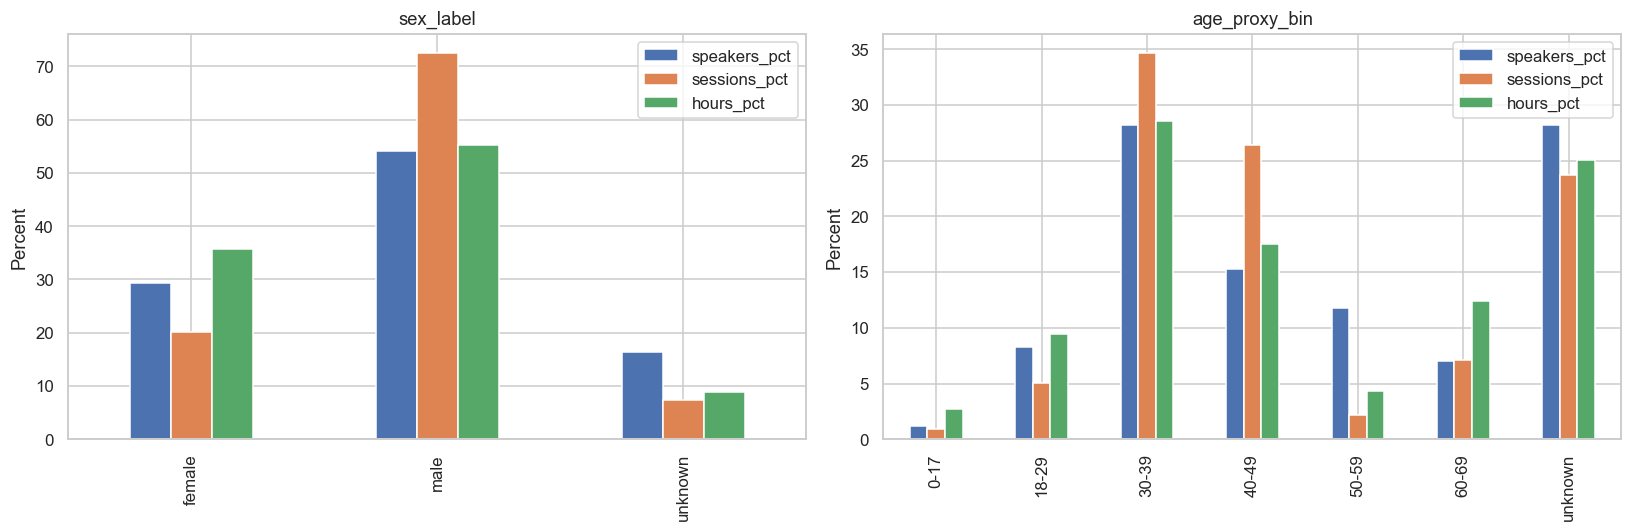

,value
gini_hours,0.666582
effective_speakers_hours,29.203518
top_1_speaker_hour_share,0.061228
top_5_speaker_hour_share,0.268766
top_10_speaker_hour_share,0.477130


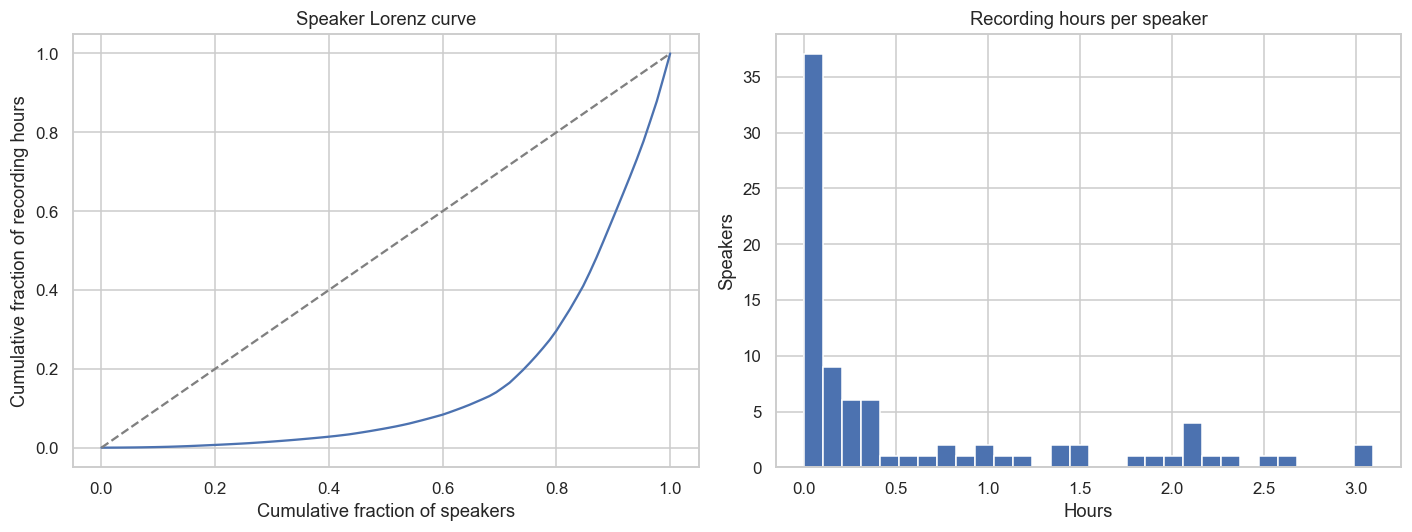

In [4]:
df['sex_label']=df.biological_sex.fillna('unknown').replace({'unspecified':'unknown','':'unknown'})
df['age_proxy_2026']=2026-df.year_of_birth
df['invalid_birth_year']=df.year_of_birth.notna() & ((df.year_of_birth>2026)|(df.year_of_birth<1906)|(df.year_of_birth%1!=0))
df.loc[df.invalid_birth_year,'age_proxy_2026']=np.nan
df['age_proxy_bin']=pd.cut(df.age_proxy_2026,[0,18,30,40,50,60,70,121],right=False,labels=['0-17','18-29','30-39','40-49','50-59','60-69','70-120']).astype('object').fillna('unknown')
def one_or_conflict(s):
    vals=s.dropna().unique()
    return vals[0] if len(vals)==1 else ('conflicting' if len(vals)>1 else 'unknown')
speaker=df.groupby('user_id').agg(sessions=('session_id','size'),seconds=('session_duration','sum'),words=('words_count','sum'),sex_label=('sex_label',one_or_conflict),age_proxy_bin=('age_proxy_bin',one_or_conflict),quality_median=('quality_score','median'),birth_year_values=('year_of_birth',lambda s:s.nunique())).reset_index()
speaker['hours']=speaker.seconds/3600
export(speaker,'speaker_summary')
balance=[]
for field in ['sex_label','age_proxy_bin']:
    a=df.groupby(field,dropna=False).agg(sessions=('session_id','size'),hours=('session_duration',lambda s:s.sum()/3600))
    b=speaker.groupby(field,dropna=False).size().rename('speakers')
    tab=a.join(b,how='outer').fillna(0).reset_index(); tab['field']=field
    for c in ['sessions','hours','speakers']: tab[c+'_pct']=100*tab[c]/tab[c].sum()
    tab=tab.rename(columns={field:'category'}); balance.append(tab)
balance=pd.concat(balance,ignore_index=True); export(balance,'demographic_balance'); display(balance)
cross=speaker.groupby(['sex_label','age_proxy_bin']).agg(speakers=('user_id','size'),hours=('hours','sum')).reset_index(); export(cross,'demographic_intersections'); display(cross)
fig,axes=plt.subplots(1,2,figsize=(15,5))
for ax,field in zip(axes,['sex_label','age_proxy_bin']):
    tab=balance[balance.field==field].set_index('category')
    tab[['speakers_pct','sessions_pct','hours_pct']].plot.bar(ax=ax); ax.set(title=field,ylabel='Percent',xlabel='')
savefig('demographic_weighting')
hours=np.sort(speaker.hours.to_numpy()); shares=hours/hours.sum(); n=len(hours)
gini=float((2*np.arange(1,n+1)-n-1)@hours/(n*hours.sum()))
concentration={'gini_hours':gini,'effective_speakers_hours':float(1/(shares@shares)),**{f'top_{k}_speaker_hour_share':float(shares[-k:].sum()) for k in [1,5,10]}}
display(pd.Series(concentration).to_frame('value'))
fig,axes=plt.subplots(1,2,figsize=(13,5)); axes[0].plot(np.r_[0,np.arange(1,n+1)/n],np.r_[0,np.cumsum(shares)]); axes[0].plot([0,1],[0,1],'--',color='gray'); axes[0].set(title='Speaker Lorenz curve',xlabel='Cumulative fraction of speakers',ylabel='Cumulative fraction of recording hours')
axes[1].hist(speaker.hours,bins=30); axes[1].set(title='Recording hours per speaker',xlabel='Hours',ylabel='Speakers'); savefig('speaker_concentration')


## 4. Transcript content, timing, repetition, and alignment
Normalization v1 uses NFKC, case folding, removal of Unicode marks/punctuation, and whitespace folding. It is only for duplicate screening; originals remain in the tables. Token counts are whitespace-based, not Hebrew morphology or phoneme coverage. Alignment scores and word probabilities are model outputs, not independently measured transcript accuracy.

,metric,flagged,denominator,pct
0,session_score_lt_0.3,74,2398,3.085905
1,segment_score_lt_0.5,3853,54122,7.119101
2,word_probability_lt_0.5,38881,325152,11.957792
3,vtt_normalized_mismatch,214,2398,8.924103
4,manifest_word_count_mismatch,0,2398,0.000000


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
char_count,2398.0,NaN,NaN,NaN,811.010425,1240.957043,2.0,96.0,397.0,1027.5,16733.0
whitespace_words,2398.0,NaN,NaN,NaN,135.895329,208.681976,1.0,16.0,67.0,170.75,2865.0
hebrew_letter_fraction,2397.0,NaN,NaN,NaN,0.989602,0.045186,0.0,1.0,1.0,1.0,1.0
has_latin,2398,2,False,1910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_digits,2398,2,True,1318,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_niqqud,2398,2,False,2250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_question,2398,2,False,2352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
empty_text,2398,1,False,2398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wpm_full_recording,2398.0,NaN,NaN,NaN,107.858986,148.426211,0.531208,92.578987,105.468973,118.149426,7279.411765
wpm_aligned,2371.0,NaN,NaN,NaN,162.217344,302.947167,33.707865,125.370698,141.42049,157.518963,10704.545455


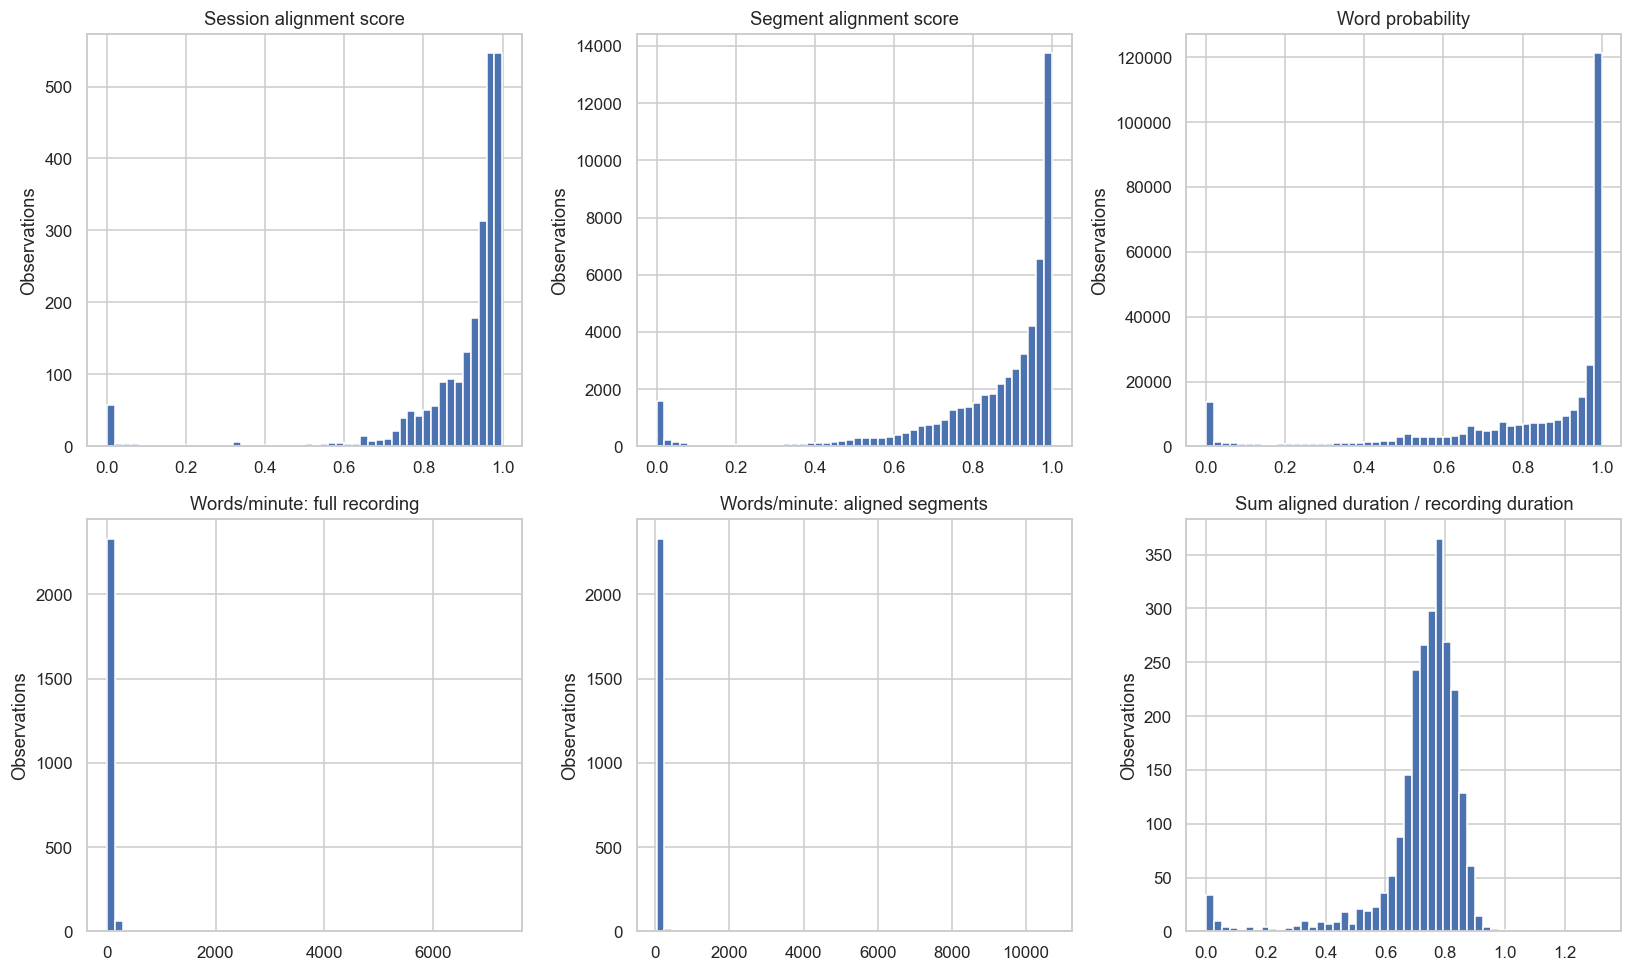

Unique normalized whitespace tokens: 61968


,normalized_text,segments,sessions,speakers
43847,עם זאת,80,76,30
46151,קישורים חיצוניים,77,77,30
18108,היסטוריה,67,67,32
9798,בנוסף,62,60,24
32657,כמו כן,50,47,23
6259,באתר הארץ,42,25,13
7652,ביוגרפיה,40,40,22
20973,הערות שוליים ==,38,38,17
34258,לדוגמה,26,22,13
35395,למשל,26,22,14


,document_source_type,document_title,sessions,speakers,hours
107,wiki-article,גביע העולם בכדורגל,82,1,1.302076
147,wiki-article,הארי פוטר,82,2,1.191287
74,wiki-article,"בוריס השלישי, מלך בולגריה",9,1,0.903644
134,wiki-article,דינמיקה של אופניים ואופנועים,34,1,0.845402
409,wiki-article,קריפטוגרפיה,10,1,0.776434
192,wiki-article,ורשה,4,1,0.745726
171,wiki-article,הסכסוך הישראלי-ערבי,19,1,0.663647
330,wiki-article,נצרות,20,1,0.659310
112,wiki-article,גלגלצ,2,1,0.580853
210,wiki-article,חמאס,13,1,0.557436


,feature,count,mean,std,min,1%,5%,50%,95%,99%,max,entity
0,duration_s,54122.0,2.425471,1.427297,0.000000,0.000000,0.340000,2.360000,4.860000,6.320000,19.28,segment
1,gap_before_s,54122.0,0.868366,2.834772,0.000000,0.000000,0.000000,0.660000,2.060000,3.280000,253.92,segment
2,word_count,54122.0,6.007760,2.864695,1.000000,1.000000,2.000000,6.000000,11.000000,12.000000,24.00,segment
3,wpm_aligned,52731.0,173.376379,379.210453,12.820513,60.331861,87.591241,151.515152,250.000000,473.684211,30000.00,segment
4,duration_s,325152.0,0.375451,0.256884,0.000000,0.000000,0.060000,0.360000,0.800000,1.280000,4.84,word
5,probability,325152.0,0.808600,0.267279,0.000000,0.000000,0.057428,0.938639,0.999349,0.999837,1.00,word


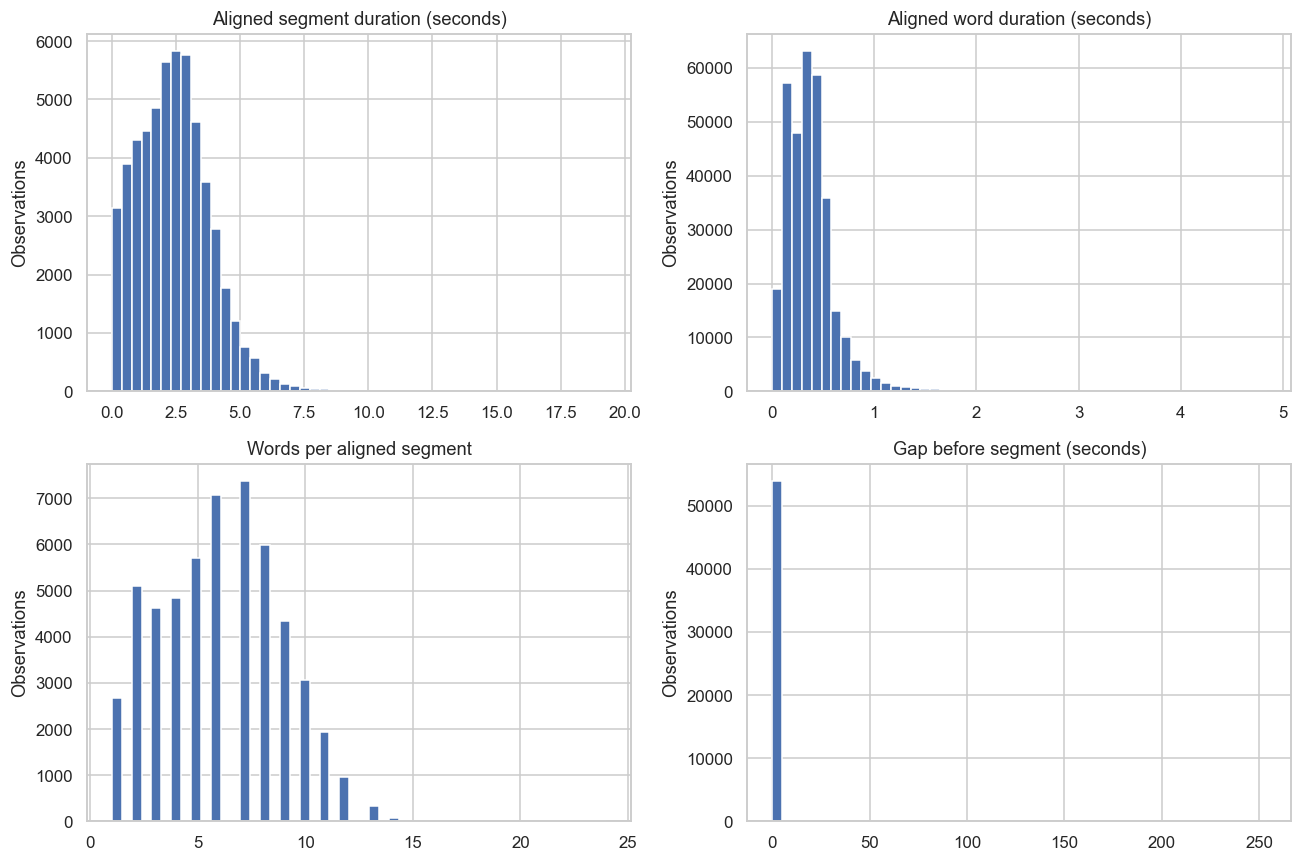

In [5]:
seg=seg.merge(df[['session_id','user_id']],on='session_id',validate='many_to_one')
seg['wpm_aligned']=60*seg.word_count/seg.duration_s.replace(0,np.nan)
duration_stats=seg.groupby('session_id').agg(aligned_duration_sum_s=('duration_s','sum'),segment_gap_sum_s=('gap_before_s','sum'),aligned_word_count=('word_count','sum'))
df=df.join(duration_stats,on='session_id')
df['alignment_duration_fraction']=df.aligned_duration_sum_s/df.session_duration
df['wpm_full_recording']=60*df.aligned_word_count/df.session_duration
df['wpm_aligned']=60*df.aligned_word_count/df.aligned_duration_sum_s.replace(0,np.nan)
df['word_count_difference']=df.aligned_word_count-df.words_count
quality_summary=pd.DataFrame({'metric':['session_score_lt_0.3','segment_score_lt_0.5','word_probability_lt_0.5','vtt_normalized_mismatch','manifest_word_count_mismatch'],
 'flagged':[int((df.quality_score<.3).sum()),int((qs.probability<.5).sum()),int((word.probability<.5).sum()),int((~df.vtt_normalized_match).sum()),int((df.word_count_difference!=0).sum())],
 'denominator':[int(df.quality_score.notna().sum()),int(qs.probability.notna().sum()),int(word.probability.notna().sum()),len(textdf),len(df)]})
quality_summary['pct']=100*quality_summary.flagged/quality_summary.denominator; export(quality_summary,'alignment_screening'); display(quality_summary)
duplicates=seg[seg.normalized_text.ne('')].groupby('normalized_text').agg(segments=('session_id','size'),sessions=('session_id','nunique'),speakers=('user_id','nunique')).reset_index().sort_values('segments',ascending=False)
export(duplicates[duplicates.segments>1],'repeated_segment_texts')
session_dups=df[df.normalized_text.ne('') & df.normalized_text.duplicated(False)].sort_values('normalized_text'); export(session_dups[['session_id','user_id','normalized_text']],'duplicate_session_texts')
tokens=Counter(t for text in df.normalized_text.fillna('') for t in text.split()); export(pd.DataFrame(tokens.most_common(),columns=['token','count']),'token_frequencies')
text_summary=df[['char_count','whitespace_words','hebrew_letter_fraction','has_latin','has_digits','has_niqqud','has_question','empty_text','wpm_full_recording','wpm_aligned','alignment_duration_fraction']].describe(include='all').T
display(text_summary); export(text_summary.reset_index(names='field'),'transcript_summary')
fig,axes=plt.subplots(2,3,figsize=(15,9))
for ax,(title,values) in zip(axes.flat,[('Session alignment score',df.quality_score),('Segment alignment score',qs.probability),('Word probability',word.probability),('Words/minute: full recording',df.wpm_full_recording),('Words/minute: aligned segments',df.wpm_aligned),('Sum aligned duration / recording duration',df.alignment_duration_fraction)]):
    ax.hist(values.replace([np.inf,-np.inf],np.nan).dropna(),bins=50); ax.set(title=title,ylabel='Observations')
savefig('transcripts_and_alignment')
print('Unique normalized whitespace tokens:',len(tokens)); display(duplicates.head(15))
doc_summary=df.groupby(['document_source_type','document_title'],dropna=False).agg(sessions=('session_id','size'),speakers=('user_id','nunique'),hours=('session_duration',lambda s:s.sum()/3600)).reset_index().sort_values('hours',ascending=False)
export(doc_summary,'document_distribution'); display(doc_summary.head(10))
timing_summary=pd.concat([seg[['duration_s','gap_before_s','word_count','wpm_aligned']].describe(percentiles=[.01,.05,.5,.95,.99]).T.assign(entity='segment'),word[['duration_s','probability']].describe(percentiles=[.01,.05,.5,.95,.99]).T.assign(entity='word')]).reset_index(names='feature')
export(timing_summary,'segment_word_timing_summary'); display(timing_summary)
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,title,values in [(axes[0,0],'Aligned segment duration (seconds)',seg.duration_s),(axes[0,1],'Aligned word duration (seconds)',word.duration_s),(axes[1,0],'Words per aligned segment',seg.word_count),(axes[1,1],'Gap before segment (seconds)',seg.gap_before_s)]:
    ax.hist(values.dropna(),bins=50); ax.set(title=title,ylabel='Observations')
savefig('segment_word_timing')


## 5. Full-corpus acoustic audit
Every recording is decoded at its native sample rate for acoustic statistics. Mono energy uses channel mean, which can cancel opposing channels; channel count is retained for follow-up. RMS uses a full-scale amplitude of 1. Frame energy uses nonoverlapping 20 ms frames. Quiet thresholds are -50/-45/-40 dBFS. The 90th/10th percentile frame-energy difference is an **energy dynamic-range proxy**, not calibrated SNR, a noise estimate, or VAD. Near-full-scale samples are clipping candidates, including possible codec overshoot.

Canonical audio duplicate hashes use decoded 16 kHz mono PCM16; sample equality can detect some container/encoding variants, but different lossy encodings need not hash identically. SHA-256 file hashes also remain available. No denoising or source rewriting occurs.

Decoded 100/2398 sessions; 0.3 minutes


Decoded 200/2398 sessions; 0.7 minutes


Decoded 300/2398 sessions; 0.9 minutes


Decoded 400/2398 sessions; 1.1 minutes


Decoded 500/2398 sessions; 1.3 minutes


Decoded 600/2398 sessions; 1.7 minutes


... (16 outputs left out)

Decoded 2300/2398 sessions; 7.1 minutes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,2398,2398,00Kkty6u7kGDjQMoRPs9L,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decode_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
codec,2398,2,opus,2274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sample_rate,2398.0,NaN,NaN,NaN,47430.275229,4114.720261,16000.0,48000.0,48000.0,48000.0,48000.0
channels,2398.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
decoded_duration_s,2398.0,NaN,NaN,NaN,75.653319,113.631866,0.12,9.42,38.07675,95.22,1459.8
peak,2398.0,NaN,NaN,NaN,0.875591,0.207793,0.0,0.80225,0.967139,1.01268,1.163406
rms_dbfs,2398.0,NaN,NaN,NaN,-24.281951,22.177127,-240.0,-23.870899,-22.443326,-18.700233,-12.269193
dc_offset,2398.0,NaN,NaN,NaN,0.0,0.000016,-0.000134,-0.000004,0.0,0.000005,0.000161
near_fullscale_fraction,2398.0,NaN,NaN,NaN,0.000009,0.000039,0.0,0.0,0.0,0.000001,0.00059


Decode failures: 0


,codec,sample_rate,channels,sessions,decoded_hours
0,aac,16000,1,39,1.033049
1,aac,24000,1,2,0.003401
2,aac,44100,1,18,1.214642
3,aac,48000,1,65,1.999200
4,opus,48000,1,2274,46.143223


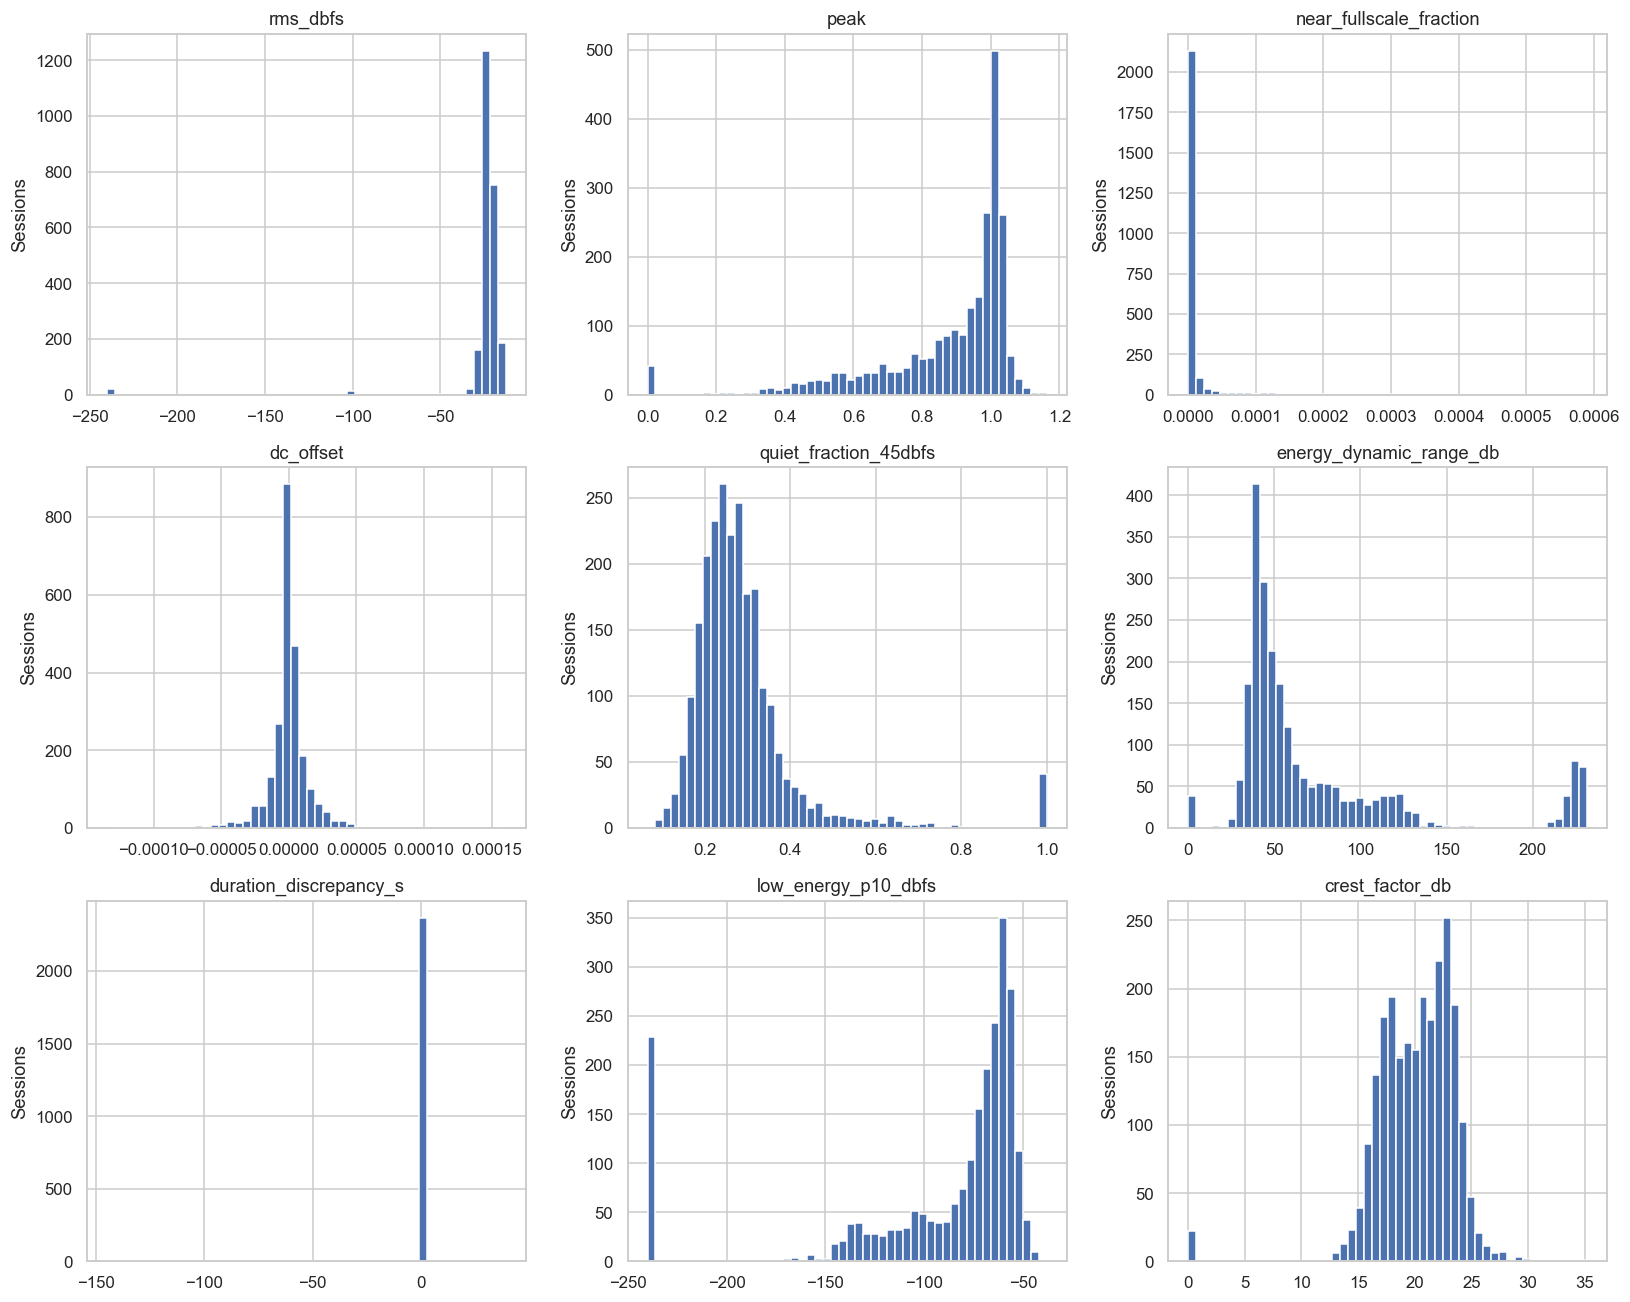

,count,mean,std,min,25%,50%,75%,max
quiet_fraction_50dbfs,2398.0,0.252788,0.136471,0.008187,0.182969,0.228334,0.279090,1.0
quiet_fraction_45dbfs,2398.0,0.290224,0.133491,0.065934,0.217612,0.264103,0.318426,1.0
quiet_fraction_40dbfs,2398.0,0.336908,0.131238,0.091575,0.260070,0.311821,0.372453,1.0


In [6]:
from concurrent.futures import ProcessPoolExecutor
from audio_eda import measure_audio
t0=time.monotonic(); audio_rows=[]
with ProcessPoolExecutor(max_workers=2) as pool:
    futures={pool.submit(measure_audio,(str(SNAPSHOT),sid)):sid for sid in df.session_id}
    for future in as_completed(futures):
        audio_rows.append(future.result())
        if len(audio_rows)%100==0:
            print(f'Decoded {len(audio_rows)}/{len(df)} sessions; {(time.monotonic()-t0)/60:.1f} minutes',flush=True)
            export(pd.DataFrame(audio_rows),'audio_progress')
audio=pd.DataFrame(audio_rows).sort_values('session_id'); export(audio,'audio_features')
(OUT/'audio_progress.csv').unlink(missing_ok=True)
df=df.merge(audio,on='session_id',how='left',validate='one_to_one')
df['duration_discrepancy_s']=df.decoded_duration_s-df.session_duration
display(audio.describe(include='all').T); print('Decode failures:',audio.decode_error.notna().sum())
technical=audio.groupby(['codec','sample_rate','channels'],dropna=False).agg(sessions=('session_id','size'),decoded_hours=('decoded_duration_s',lambda s:s.sum()/3600)).reset_index(); export(technical,'audio_formats'); display(technical)
acoustic=['rms_dbfs','peak','near_fullscale_fraction','dc_offset','quiet_fraction_45dbfs','energy_dynamic_range_db','duration_discrepancy_s','low_energy_p10_dbfs','crest_factor_db']
fig,axes=plt.subplots(3,3,figsize=(15,12))
for ax,c in zip(axes.flat,acoustic): ax.hist(df[c].dropna(),bins=50); ax.set(title=c,ylabel='Sessions')
for ax in axes.flat[len(acoustic):]: ax.set_visible(False)
savefig('acoustic_distributions')
display(df[['quiet_fraction_50dbfs','quiet_fraction_45dbfs','quiet_fraction_40dbfs']].describe().T)


## 6. Outliers, associations, and human review queue
Robust modified Z scores use |0.6745 × (x - median) / MAD| > 3.5. If MAD is zero and IQR is positive, use 1.5 × IQR fences. If both are zero, report no robust numerical flag. Heavy tails may represent valid recordings. Comparisons are descriptive and are not hypothesis tests. Correlations across sessions can be driven by prolific speakers; a separate speaker-median correlation is provided.

,flag,flagged_sessions,all_sessions,pct
0,low_session_alignment,74,2398,3.085905
1,low_segment_alignment,787,2398,32.819016
2,duration_mismatch,35,2398,1.459550
3,decode_failure,0,2398,0.000000
4,quiet_majority,121,2398,5.045872
5,low_rms,41,2398,1.709758
6,near_fullscale_candidate,0,2398,0.000000
7,dc_offset_candidate,0,2398,0.000000
8,nonfinite_audio,0,2398,0.000000
9,invalid_birth_year,219,2398,9.132611


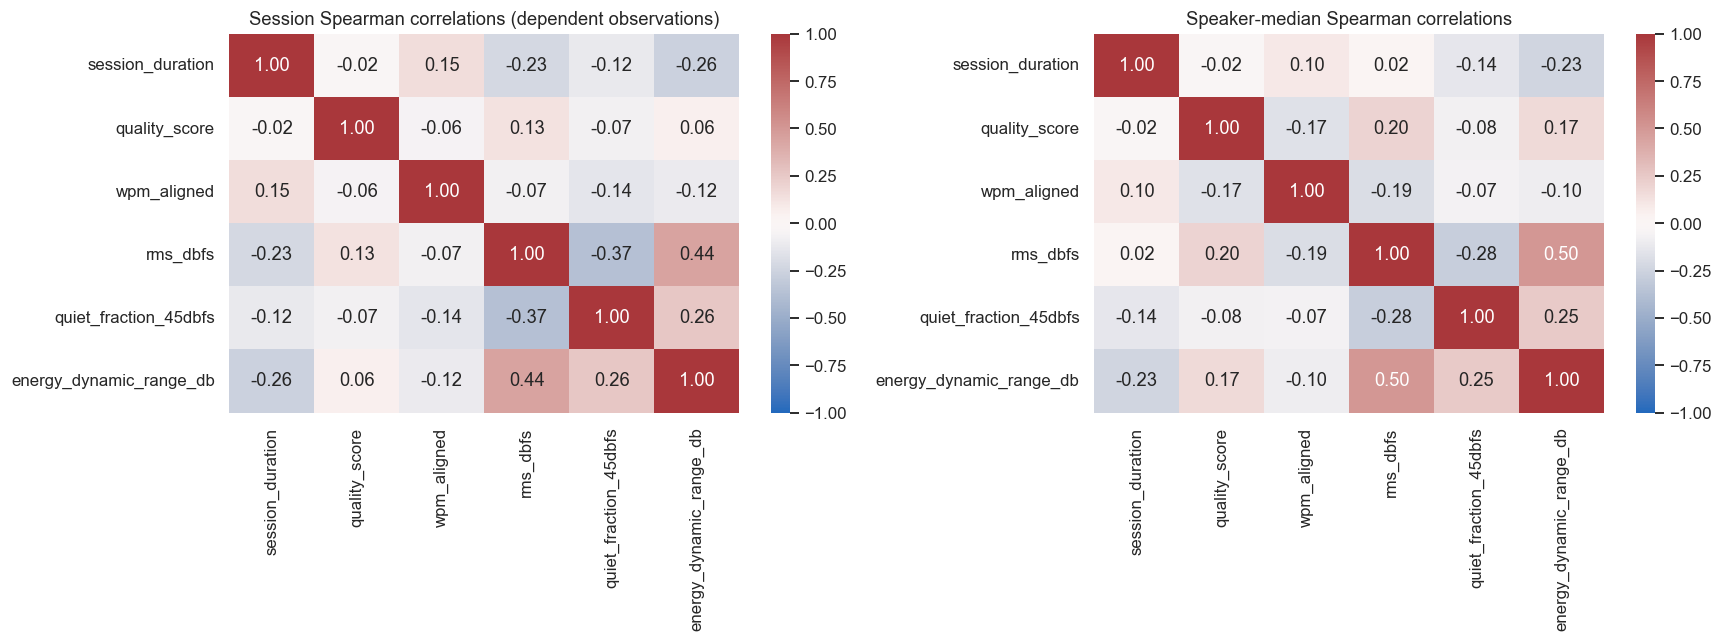

,group_field,group,sessions,speakers,hours,median_alignment,median_rms_dbfs,median_quiet_fraction,low_alignment_pct,any_flag_pct
0,sex_label,female,481,25,18.074294,0.96160,-22.990886,0.244444,1.455301,55.093555
1,sex_label,male,1739,46,27.896005,0.95310,-21.679039,0.268828,3.450259,50.086256
2,sex_label,unknown,178,14,4.503517,0.93040,-23.176696,0.274733,3.932584,43.820225
3,age_proxy_bin,0-17,22,1,1.360669,0.84040,-22.178516,0.226927,0.000000,72.727273
4,age_proxy_bin,18-29,120,7,4.755554,0.95465,-23.109169,0.228679,4.166667,56.666667
5,age_proxy_bin,30-39,831,24,14.417063,0.96740,-22.544047,0.261972,2.647413,44.404332
6,age_proxy_bin,40-49,634,13,8.848612,0.96535,-19.044417,0.264752,0.630915,42.271293
7,age_proxy_bin,50-59,53,10,2.186435,0.95160,-22.662253,0.338475,9.433962,66.037736
8,age_proxy_bin,60-69,170,6,6.276460,0.96915,-23.420598,0.325851,14.705882,55.882353
9,age_proxy_bin,unknown,568,24,12.629023,0.86820,-23.079027,0.255297,2.288732,63.908451


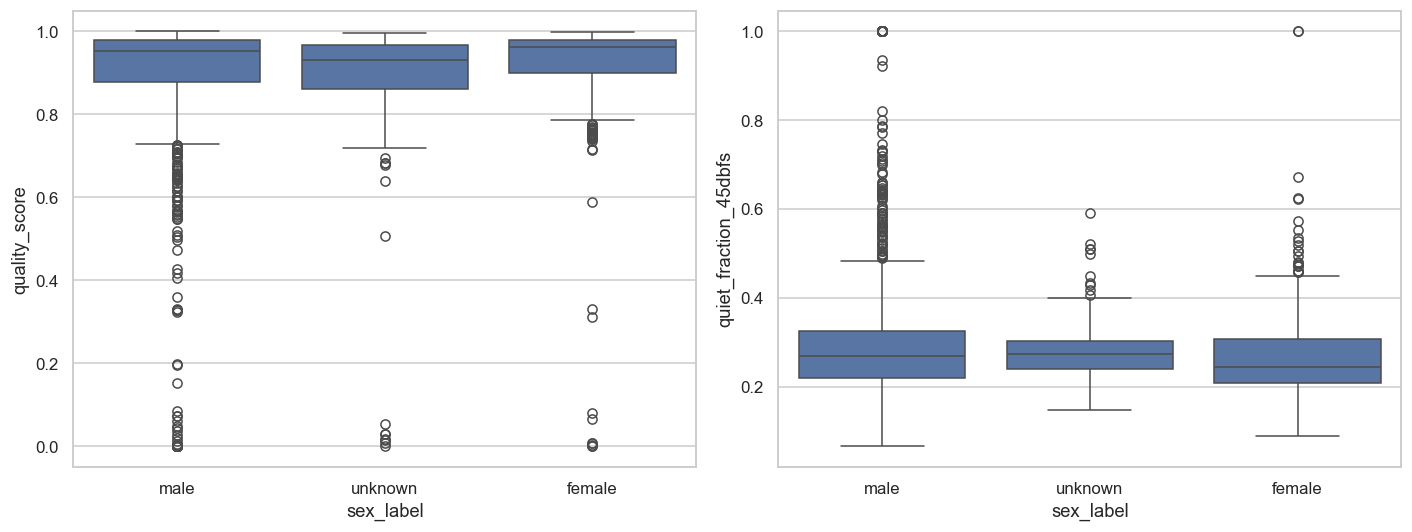

,session_id,quality_score,rms_dbfs,review_flag_count,review_reasons
178,szfbvdXWalVdgit5JArOB,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...
244,85AzpFT3XhnWTp8q_3jmB,0.0,-52.147091,9,low_session_alignment;low_segment_alignment;qu...
480,Jxd_0xTgqyLgOVn60xKyN,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...
506,BjwXO9V539OP7mVpjZZnC,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...
706,ftuDqFSIY3qbCDjw__yh9,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...
714,VO6knYiKqVonbCMmDBvgu,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...
717,qTZNK1lEBEEiKkzU_nxsZ,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...
761,vSAz3ueFZBPF2Uc89hGrR,0.0,-103.238427,9,low_session_alignment;low_segment_alignment;qu...
1002,IRxX8HuU38PD1iwXjNrYw,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...
1004,NUz0EINdTfLRnc54MDDXI,0.0,-240.000000,9,low_session_alignment;low_segment_alignment;qu...


In [7]:
flags=pd.DataFrame({'session_id':df.session_id})
flags['low_session_alignment']=df.quality_score<.3
flags['low_segment_alignment']=df.min_segment_quality_score<.5
flags['duration_mismatch']=df.duration_discrepancy_s.abs()>np.maximum(.25,.01*df.session_duration)
flags['decode_failure']=df.decode_error.notna()
flags['quiet_majority']=df.quiet_fraction_45dbfs>.5
flags['low_rms']=df.rms_dbfs< -40
flags['near_fullscale_candidate']=df.near_fullscale_fraction>.001
flags['dc_offset_candidate']=df.dc_offset.abs()>.01
flags['nonfinite_audio']=df.nonfinite_samples.fillna(0)>0
flags['invalid_birth_year']=df.invalid_birth_year
flags['nonpositive_duration']=df.session_duration<=0
flags['empty_transcript']=df.empty_text
badids=set(checks.loc[checks.check.str.contains('timestamp|overlap|parse|missing',regex=True),'session_id'])
flags['structural_issue']=df.session_id.isin(badids)
outlier_rules=[]
for c in ['session_duration','words_count','avg_words_per_minute','wpm_aligned','rms_dbfs','quiet_fraction_45dbfs','energy_dynamic_range_db','low_energy_p10_dbfs']:
    x=df[c]; med=x.median(); mad=(x-med).abs().median(); q1,q3=x.quantile([.25,.75]); iqr=q3-q1
    if mad>0: f=(.6745*(x-med)/mad).abs()>3.5; rule='modified_z_abs_gt_3.5'
    elif iqr>0: f=(x<q1-1.5*iqr)|(x>q3+1.5*iqr); rule='IQR_1.5_fallback'
    else: f=pd.Series(False,index=x.index); rule='degenerate_no_flag'
    flags['outlier_'+c]=f.fillna(False); outlier_rules.append({'field':c,'median':med,'MAD':mad,'IQR':iqr,'rule':rule,'flagged':int(f.sum()),'observed':int(x.notna().sum())})
export(pd.DataFrame(outlier_rules),'outlier_rules'); export(flags,'session_flags')
flagcols=flags.columns.drop('session_id'); df['review_flag_count']=flags[flagcols].sum(axis=1)
df['review_reasons']=flags[flagcols].apply(lambda row:';'.join(row.index[row.astype(bool)]),axis=1)
df['audio_path']=df.session_id.map(lambda sid:str(SNAPSHOT/sid/'audio.mka'))
review=df[df.review_flag_count>0].sort_values(['review_flag_count','quality_score'],ascending=[False,True])
export(review,'review_candidates'); export(df,'recording_features')
flag_summary=pd.DataFrame({'flag':flagcols,'flagged_sessions':[int(flags[c].sum()) for c in flagcols]}); flag_summary['all_sessions']=len(df); flag_summary['pct']=100*flag_summary.flagged_sessions/len(df); export(flag_summary,'flag_summary'); display(flag_summary)
sample=df.groupby('user_id',group_keys=False).sample(n=1,random_state=SEED)
sample=sample.assign(review_role='speaker_spanning_baseline',human_review_status='pending',human_noise_rating='',human_text_match='',human_notes='')
export(sample[['session_id','user_id','audio_path','review_role','human_review_status','human_noise_rating','human_text_match','human_notes']],'human_listening_sample')
corrfields=['session_duration','quality_score','wpm_aligned','rms_dbfs','quiet_fraction_45dbfs','energy_dynamic_range_db']
session_corr=df[corrfields].corr(method='spearman'); speaker_corr=df.groupby('user_id')[corrfields].median().corr(method='spearman')
export(session_corr.reset_index(names='field'),'session_spearman'); export(speaker_corr.reset_index(names='field'),'speaker_median_spearman')
fig,axes=plt.subplots(1,2,figsize=(16,6))
sns.heatmap(session_corr,ax=axes[0],vmin=-1,vmax=1,cmap='vlag',annot=True,fmt='.2f'); axes[0].set_title('Session Spearman correlations (dependent observations)')
sns.heatmap(speaker_corr,ax=axes[1],vmin=-1,vmax=1,cmap='vlag',annot=True,fmt='.2f'); axes[1].set_title('Speaker-median Spearman correlations'); savefig('correlations')
groups=[]
for c in ['sex_label','age_proxy_bin','document_source_type','codec','sample_rate']:
    for label,g in df.groupby(c,dropna=False):
        groups.append({'group_field':c,'group':label,'sessions':len(g),'speakers':g.user_id.nunique(),'hours':g.session_duration.sum()/3600,'median_alignment':g.quality_score.median(),'median_rms_dbfs':g.rms_dbfs.median(),'median_quiet_fraction':g.quiet_fraction_45dbfs.median(),'low_alignment_pct':100*(g.quality_score<.3).mean(),'any_flag_pct':100*(g.review_flag_count>0).mean()})
groupdf=pd.DataFrame(groups); export(groupdf,'group_quality_comparisons'); display(groupdf)
fig,axes=plt.subplots(1,2,figsize=(13,5)); sns.boxplot(data=df,x='sex_label',y='quality_score',ax=axes[0]); sns.boxplot(data=df,x='sex_label',y='quiet_fraction_45dbfs',ax=axes[1]); savefig('quality_by_source_sex_label')
display(review[['session_id','quality_score','rms_dbfs','review_flag_count','review_reasons']].head(15))


### Listening examples for human review
These short clips are provided for a human reviewer. The analysis has not assigned perceptual noise or transcript-correctness ratings. Two flagged examples and two seeded baseline sessions are embedded, capped at 15 seconds each; the complete review lists retain original paths.

In [8]:
examples=pd.concat([review.head(2).assign(example_role='flagged'),sample.head(2).assign(example_role='baseline')]).drop_duplicates('session_id')
for _,r in examples.iterrows():
    print(r.example_role,r.session_id,'alignment score:',r.quality_score)
    try:
        with av.open(str(SNAPSHOT/r.session_id/'audio.mka')) as container:
            stream=container.streams.audio[0]; rate=stream.codec_context.sample_rate
            convert=av.AudioResampler(format='fltp',layout='mono',rate=rate); clip=[]; count=0
            for frame in container.decode(stream):
                for f in convert.resample(frame):
                    x=f.to_ndarray().ravel(); clip.append(x); count+=len(x)
                if count>=15*rate: break
            display(Audio(np.concatenate(clip)[:15*rate],rate=rate,normalize=False))
    except Exception as e: print('Listening clip unavailable:',type(e).__name__,str(e))


flagged szfbvdXWalVdgit5JArOB alignment score: 0.0


flagged 85AzpFT3XhnWTp8q_3jmB alignment score: 0.0


baseline LcFIFvS8YXz5U8B819JKh alignment score: 0.9577


baseline gFhoAf2QFaJLmqVoKkb6E alignment score: 0.894


Listening clip unavailable: ValueError Audio data must be between -1 and 1 when normalize=False.


## 7. Exact duplicates and split feasibility
This audit models a strict protocol requiring both speaker and exact normalized segment text separation. Speakers are joined when they share a nonempty normalized segment. All recordings of each speaker therefore remain together. Tiny/common text can create large components; the audit shows feasibility, not a final split. Near-duplicate/paraphrase and perceptual speaker-identity checks remain unperformed.

In [9]:
filedup=inventory[inventory.path.str.endswith('/audio.mka')].copy()
filedup=filedup[filedup.sha256.duplicated(False)]; export(filedup,'duplicate_audio_files')
pcmdup=audio[audio.pcm16_16k_mono_sha256.notna() & audio.pcm16_16k_mono_sha256.duplicated(False)].sort_values('pcm16_16k_mono_sha256'); export(pcmdup,'duplicate_canonical_audio')
parent={u:u for u in speaker.user_id}
def find(x):
    while parent[x]!=x: parent[x]=parent[parent[x]]; x=parent[x]
    return x
def union(a,b):
    a,b=find(a),find(b)
    if a!=b: parent[b]=a
for text,g in seg[seg.normalized_text.ne('')].groupby('normalized_text'):
    users=g.user_id.unique()
    for u in users[1:]: union(users[0],u)
speaker['text_component']=speaker.user_id.map(find)
components=speaker.groupby('text_component').agg(speakers=('user_id','size'),sessions=('sessions','sum'),hours=('hours','sum')).reset_index().sort_values('hours',ascending=False)
components['hour_share']=components.hours/components.hours.sum(); export(components,'speaker_text_components'); export(speaker,'speaker_summary')
print('Duplicate source-audio files:',len(filedup),'Canonical duplicate recordings:',len(pcmdup))
print('Shared normalized segment texts across speakers:',int((duplicates.speakers>1).sum())); display(components.head(15))


Duplicate source-audio files: 0 Canonical duplicate recordings: 0
Shared normalized segment texts across speakers: 659


,text_component,speakers,sessions,hours,hour_share
7,c913dcb1-93b0-4652-b9ab-08b56c5a4eb3,74,2366,50.084352,0.992284
4,9b24c9cf-1262-4c28-9570-d57c8dd34e1e,1,1,0.219625,0.004351
1,5a394a0c-4550-413b-b76f-db2266f77171,1,3,0.040201,0.000796
6,bd783e59-9137-46e8-9755-04d4767ac6a3,1,4,0.029956,0.000593
11,f2d52bcc-9911-41ae-adb3-4387e39ae289,1,4,0.026921,0.000533
0,04d374d1-9317-4cf1-9961-158385f3f9f0,1,11,0.021245,0.000421
2,72063563-00ed-4c5a-84f7-1b55b009071a,1,1,0.019830,0.000393
9,db24cb62-b45e-494a-b291-a851d4bfaa4f,1,4,0.011817,0.000234
5,a90b45a7-9a55-4832-b1d4-83b0d0ffc57e,1,1,0.007619,0.000151
3,7d5e2e80-2dec-48d4-841f-aa09bd83030c,1,1,0.005855,0.000116


## 8. Findings, limitations, and reproducibility
The following report is generated from this run. Acoustic screening has no human-confirmed noise labels. No ASR WER, calibrated SNR, perceived naturalness, accent, inferred demographics, or proof of single-speaker content is claimed. Full listening verification and near-duplicate detection remain follow-up work. Automatic confidence is not independent validation. No data were removed or models fitted.

References: [dataset card](https://huggingface.co/datasets/ivrit-ai/crowd-recital), [NIST outlier guidance](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm), [Common Voice methodology](https://github.com/common-voice/cv-dataset/blob/main/datasets/scripted-speech/README.md).

In [10]:
largest=float(components.hour_share.max()) if len(components) else 0
metrics={**overview,**concentration,'decode_success':int(df.decode_error.isna().sum()),'decode_failure':int(df.decode_error.notna().sum()),'flagged_sessions':len(review),'low_alignment_sessions':int((df.quality_score<.3).sum()),'sex_unknown_speakers':int((speaker.sex_label=='unknown').sum()),'birth_year_missing_sessions':int(df.year_of_birth.isna().sum()),'largest_speaker_text_component_hour_share':largest,'exact_duplicate_audio_files':len(filedup),'canonical_duplicate_recordings':len(pcmdup),'vtt_normalized_mismatches':int((~df.vtt_normalized_match).sum()),'integrity_issue_rows':len(checks),'manifest_metadata_disagreements':len(diff),'vocabulary_size':len(tokens)}
(OUT/'key_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
def table_markdown(frame):
    # Avoid optional tabulate dependency.
    columns=list(frame.columns); rows=['| '+' | '.join(map(str,columns))+' |','| '+' | '.join(['---']*len(columns))+' |']
    for row in frame.itertuples(index=False,name=None): rows.append('| '+' | '.join(str(round(x,3)) if isinstance(x,(float,np.floating)) else str(x).replace('|','/') for x in row)+' |')
    return '\n'.join(rows)
report=f'''# Crowd-recital EDA: progress and findings

## Completed work
- Inspected the workspace, supplied research-context PDF, dataset documentation, manifest and JSON structure.
- Ran the user-requested Hugging Face download command before EDA execution and documented the analysis design in EDA_PLAN.md.
- Analyzed revision `{SNAPSHOT.name}` locally; credentials are never included in outputs.
- Inventoried and SHA-256 hashed {len(inventory):,} files; checked companion presence, schema, IDs, metadata agreement, transcript and word timing.
- Built recording, speaker, segment, word, alignment, acoustic, review, and split-connectivity tables.
- Decoded {metrics['decode_success']:,}/{len(df):,} recordings successfully; {metrics['decode_failure']} failures retained explicitly.
- Generated feature distributions, demographic weighting, speaker concentration, transcript/alignment, acoustic, association, and outlier analyses.
- Saved tables, plots and provenance under `eda_outputs/`. The executed notebook is `dataset.ipynb`.

## Corpus size and concentration
{len(df):,} sessions, {overview['speakers']:,} speakers, {overview['hours']:.2f} reported recording hours, {overview['manifest_words']:,} manifest words and {overview['manifest_segments']:,} manifest segments. Recomputed aligned counts: {len(word):,} word objects and {len(seg):,} segments; these are separate counting conventions.

The top speaker contributes {concentration['top_1_speaker_hour_share']:.1%} of hours; the top five {concentration['top_5_speaker_hour_share']:.1%}; the top ten {concentration['top_10_speaker_hour_share']:.1%}. Hour-based Gini is {gini:.3f}, and the effective speaker count is {concentration['effective_speakers_hours']:.1f}. These quantify contribution imbalance without assuming a population demographic target.

## Demographic distributions
The dataset labels biological sex, not gender identity. Age at recording cannot be established because a reliable recording date is unavailable. The age proxy is 2026 minus birth year and must not be used as observed age. Unknown sex: {metrics['sex_unknown_speakers']} speakers. Missing birth year: {metrics['birth_year_missing_sessions']} sessions. Conflicting speaker metadata is retained as a category.

{table_markdown(balance)}

## Alignment and acoustic screening
{table_markdown(quality_summary)}

{table_markdown(technical)}

{table_markdown(flag_summary[~flag_summary.flag.str.startswith('outlier_')])}

There are {len(review):,} sessions with at least one screening flag. Flags overlap and include provider segment-confidence guidance, so their sum is not a rejection count. See `outlier_rules.csv` for robust numerical thresholds and `review_candidates.csv` for all reasons. Quiet fractions depend on the documented energy threshold. Energy dynamic range is not SNR. Near-full-scale values may reflect lossy overshoot, so clipping candidates need listening and waveform review.

## Integrity, repetitions, and split risk
{len(checks):,} integrity issue occurrences and {len(diff):,} manifest/metadata disagreement entries were retained for review. There are {len(filedup)} recordings participating in exact file duplicates and {len(pcmdup)} in canonical PCM duplicates; these are recording counts, not duplicate-group counts. There are {int((duplicates.speakers>1).sum()):,} exact normalized segment texts shared across speakers. The largest strict speaker/text connected component accounts for {largest:.1%} of recording hours, which constrains a split requiring both speaker and exact text independence. No split was assigned.

## Recommended actions
1. Review decode, timestamp and metadata integrity issues before selecting training data; retain documented reasons and original files.
2. Listen to the flagged queue and `human_listening_sample.csv`, which selects one seeded baseline session per speaker. Human ratings are pending; no perceptual-noise claim is established.
3. Select demographic and speaker-duration quotas with unknowns visible. Evaluate retention rates by speakers and hours, not just session counts, before setting exclusions.
4. Confirm alignment/text mismatches manually. Provider scores measure alignment, and are not measured WER or transcript ground truth.
5. Establish speaker/text grouping and verify largest-component feasibility before freezing evaluation splits. Browser codec, sample rate, channel and source signatures can confound a future real/synthetic experiment.
6. Obtain reliable demographic provenance or recording dates if gender, accent or age-at-recording analyses are required. Do not infer them from voice.

## Limits and remaining human work
This is a descriptive audit of read Hebrew, not a representative sample of Hebrew speakers or spontaneous speech. Sessions repeat speakers and documents; no independent-session significance tests or causal claims were made. Vocabulary is whitespace-based rather than morphological/phonemic coverage. Exact normalization can merge distinctions; perceptual audio duplicates, paraphrases, stable cross-ID speaker identity, speech/noise separation, calibrated SNR, ASR WER, single-speaker verification and human listening are not established. No acoustic denoising, automatic exclusion, synthetic generation or classifier training was performed.

## Reproduction and references
Open `dataset.ipynb` in this project and run all cells using the recorded package versions in `eda_outputs/run_provenance.json`. Set `CROWD_RECITAL_PATH` to move the same input revision. The notebook requires no network after acquisition. Original bytes are hashed in `file_inventory.csv`; current source hashes do not independently authenticate upstream provenance.

- Dataset schema and provider screening guidance: https://huggingface.co/datasets/ivrit-ai/crowd-recital
- Robust outlier screening and cautions: https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
- Comparative demographic/speaker reporting methodology: https://github.com/common-voice/cv-dataset/blob/main/datasets/scripted-speech/README.md
'''
(ROOT/'EDA_PROGRESS.md').write_text(report,encoding='utf-8')
run['completed_utc']=pd.Timestamp.now(tz='UTC').isoformat(); run['metrics']=metrics
(OUT/'run_provenance.json').write_text(json.dumps(run,indent=2),encoding='utf-8')
display(Markdown(report))
assert len(audio)==len(manifest) and df.session_id.is_unique
assert len(seg)==sum(len(a.get('segments',[])) for a in aligned.values())
print('Analysis artifacts:',len(list(OUT.glob('*.csv'))),'CSV tables;',len(list(FIG.glob('*.png'))),'figures')


# Crowd-recital EDA: progress and findings

## Completed work
- Inspected the workspace, supplied research-context PDF, dataset documentation, manifest and JSON structure.
- Ran the user-requested Hugging Face download command before EDA execution and documented the analysis design in EDA_PLAN.md.
- Analyzed revision `34d93a876ae075a1a7904e7ec2c54d2af1c9d4d7` locally; credentials are never included in outputs.
- Inventoried and SHA-256 hashed 9,597 files; checked companion presence, schema, IDs, metadata agreement, transcript and word timing.
- Built recording, speaker, segment, word, alignment, acoustic, review, and split-connectivity tables.
- Decoded 2,398/2,398 recordings successfully; 0 failures retained explicitly.
- Generated feature distributions, demographic weighting, speaker concentration, transcript/alignment, acoustic, association, and outlier analyses.
- Saved tables, plots and provenance under `eda_outputs/`. The executed notebook is `dataset.ipynb`.

## Corpus size and concentration
2,398 sessions, 85 speakers, 50.47 reported recording hours, 325,152 manifest words and 54,122 manifest segments. Recomputed aligned counts: 325,152 word objects and 54,122 segments; these are separate counting conventions.

The top speaker contributes 6.1% of hours; the top five 26.9%; the top ten 47.7%. Hour-based Gini is 0.667, and the effective speaker count is 29.2. These quantify contribution imbalance without assuming a population demographic target.

## Demographic distributions
The dataset labels biological sex, not gender identity. Age at recording cannot be established because a reliable recording date is unavailable. The age proxy is 2026 minus birth year and must not be used as observed age. Unknown sex: 14 speakers. Missing birth year: 349 sessions. Conflicting speaker metadata is retained as a category.

| category | sessions | hours | speakers | field | sessions_pct | hours_pct | speakers_pct |
| --- | --- | --- | --- | --- | --- | --- | --- |
| female | 481 | 18.074 | 25 | sex_label | 20.058 | 35.809 | 29.412 |
| male | 1739 | 27.896 | 46 | sex_label | 72.519 | 55.268 | 54.118 |
| unknown | 178 | 4.504 | 14 | sex_label | 7.423 | 8.922 | 16.471 |
| 0-17 | 22 | 1.361 | 1 | age_proxy_bin | 0.917 | 2.696 | 1.176 |
| 18-29 | 120 | 4.756 | 7 | age_proxy_bin | 5.004 | 9.422 | 8.235 |
| 30-39 | 831 | 14.417 | 24 | age_proxy_bin | 34.654 | 28.563 | 28.235 |
| 40-49 | 634 | 8.849 | 13 | age_proxy_bin | 26.439 | 17.531 | 15.294 |
| 50-59 | 53 | 2.186 | 10 | age_proxy_bin | 2.21 | 4.332 | 11.765 |
| 60-69 | 170 | 6.276 | 6 | age_proxy_bin | 7.089 | 12.435 | 7.059 |
| unknown | 568 | 12.629 | 24 | age_proxy_bin | 23.686 | 25.021 | 28.235 |

## Alignment and acoustic screening
| metric | flagged | denominator | pct |
| --- | --- | --- | --- |
| session_score_lt_0.3 | 74 | 2398 | 3.086 |
| segment_score_lt_0.5 | 3853 | 54122 | 7.119 |
| word_probability_lt_0.5 | 38881 | 325152 | 11.958 |
| vtt_normalized_mismatch | 214 | 2398 | 8.924 |
| manifest_word_count_mismatch | 0 | 2398 | 0.0 |

| codec | sample_rate | channels | sessions | decoded_hours |
| --- | --- | --- | --- | --- |
| aac | 16000 | 1 | 39 | 1.033 |
| aac | 24000 | 1 | 2 | 0.003 |
| aac | 44100 | 1 | 18 | 1.215 |
| aac | 48000 | 1 | 65 | 1.999 |
| opus | 48000 | 1 | 2274 | 46.143 |

| flag | flagged_sessions | all_sessions | pct |
| --- | --- | --- | --- |
| low_session_alignment | 74 | 2398 | 3.086 |
| low_segment_alignment | 787 | 2398 | 32.819 |
| duration_mismatch | 35 | 2398 | 1.46 |
| decode_failure | 0 | 2398 | 0.0 |
| quiet_majority | 121 | 2398 | 5.046 |
| low_rms | 41 | 2398 | 1.71 |
| near_fullscale_candidate | 0 | 2398 | 0.0 |
| dc_offset_candidate | 0 | 2398 | 0.0 |
| nonfinite_audio | 0 | 2398 | 0.0 |
| invalid_birth_year | 219 | 2398 | 9.133 |
| nonpositive_duration | 0 | 2398 | 0.0 |
| empty_transcript | 0 | 2398 | 0.0 |
| structural_issue | 171 | 2398 | 7.131 |

There are 1,214 sessions with at least one screening flag. Flags overlap and include provider segment-confidence guidance, so their sum is not a rejection count. See `outlier_rules.csv` for robust numerical thresholds and `review_candidates.csv` for all reasons. Quiet fractions depend on the documented energy threshold. Energy dynamic range is not SNR. Near-full-scale values may reflect lossy overshoot, so clipping candidates need listening and waveform review.

## Integrity, repetitions, and split risk
2,856 integrity issue occurrences and 0 manifest/metadata disagreement entries were retained for review. There are 0 recordings participating in exact file duplicates and 0 in canonical PCM duplicates; these are recording counts, not duplicate-group counts. There are 659 exact normalized segment texts shared across speakers. The largest strict speaker/text connected component accounts for 99.2% of recording hours, which constrains a split requiring both speaker and exact text independence. No split was assigned.

## Recommended actions
1. Review decode, timestamp and metadata integrity issues before selecting training data; retain documented reasons and original files.
2. Listen to the flagged queue and `human_listening_sample.csv`, which selects one seeded baseline session per speaker. Human ratings are pending; no perceptual-noise claim is established.
3. Select demographic and speaker-duration quotas with unknowns visible. Evaluate retention rates by speakers and hours, not just session counts, before setting exclusions.
4. Confirm alignment/text mismatches manually. Provider scores measure alignment, and are not measured WER or transcript ground truth.
5. Establish speaker/text grouping and verify largest-component feasibility before freezing evaluation splits. Browser codec, sample rate, channel and source signatures can confound a future real/synthetic experiment.
6. Obtain reliable demographic provenance or recording dates if gender, accent or age-at-recording analyses are required. Do not infer them from voice.

## Limits and remaining human work
This is a descriptive audit of read Hebrew, not a representative sample of Hebrew speakers or spontaneous speech. Sessions repeat speakers and documents; no independent-session significance tests or causal claims were made. Vocabulary is whitespace-based rather than morphological/phonemic coverage. Exact normalization can merge distinctions; perceptual audio duplicates, paraphrases, stable cross-ID speaker identity, speech/noise separation, calibrated SNR, ASR WER, single-speaker verification and human listening are not established. No acoustic denoising, automatic exclusion, synthetic generation or classifier training was performed.

## Reproduction and references
Open `dataset.ipynb` in this project and run all cells using the recorded package versions in `eda_outputs/run_provenance.json`. Set `CROWD_RECITAL_PATH` to move the same input revision. The notebook requires no network after acquisition. Original bytes are hashed in `file_inventory.csv`; current source hashes do not independently authenticate upstream provenance.

- Dataset schema and provider screening guidance: https://huggingface.co/datasets/ivrit-ai/crowd-recital
- Robust outlier screening and cautions: https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
- Comparative demographic/speaker reporting methodology: https://github.com/common-voice/cv-dataset/blob/main/datasets/scripted-speech/README.md


Analysis artifacts: 36 CSV tables; 8 figures


## 9. Analyst validation: reported versus decoded time bounds
This independent follow-up reads the exported tables so the reported-duration warnings can be distinguished from violations of actual decoded audio bounds. Birth-year placeholders are also quantified explicitly. It can be rerun without decoding the corpus again; it does not replace any earlier screening flags.

In [11]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
validation_root=Path.cwd(); validation_out=validation_root/'eda_outputs'
recordings_check=pd.read_csv(validation_out/'recording_features.csv')
segments_check=pd.read_csv(validation_out/'segments.csv')
audio_check=pd.read_csv(validation_out/'audio_features.csv')
limits=recordings_check[['session_id','session_duration','decoded_duration_s']]
timing_check=segments_check.merge(limits,on='session_id',how='left',validate='many_to_one')
timing_check['reported_duration_violation']=(timing_check.start<0)|(timing_check.end<=timing_check.start)|(timing_check.end>timing_check.session_duration+.1)
timing_check['decoded_duration_violation']=np.where(timing_check.decoded_duration_s.notna(),(timing_check.start<0)|(timing_check.end<=timing_check.start)|(timing_check.end>timing_check.decoded_duration_s+.1),None)
timing_candidates=timing_check[timing_check.reported_duration_violation | timing_check.decoded_duration_violation.fillna(False).astype(bool)]
timing_candidates.to_csv(validation_out/'timestamp_bounds_validation.csv',index=False,encoding='utf-8-sig')
birth=recordings_check.year_of_birth
invalid_birth=birth.notna() & ((birth<1906)|(birth>2026)|(birth%1!=0))
validation_metrics={
 'birth_year_zero_sessions':int((birth==0).sum()),
 'invalid_or_placeholder_birth_year_sessions':int(invalid_birth.sum()),
 'birth_year_missing_sessions':int(birth.isna().sum()),
 'age_proxy_unavailable_sessions':int((birth.isna()|invalid_birth).sum()),
 'segments_outside_reported_duration':int(timing_check.reported_duration_violation.sum()),
 'sessions_outside_reported_duration':int(timing_check.loc[timing_check.reported_duration_violation,'session_id'].nunique()),
 'segments_outside_decoded_duration':int(timing_check.decoded_duration_violation.fillna(False).sum()),
 'sessions_outside_decoded_duration':int(timing_check.loc[timing_check.decoded_duration_violation.fillna(False).astype(bool),'session_id'].nunique()),
 'segments_without_decoded_duration':int(timing_check.decoded_duration_s.isna().sum())}
display(pd.Series(validation_metrics,name='count').to_frame())
display(timing_candidates[['session_id','segment_index','start','end','session_duration','decoded_duration_s','reported_duration_violation','decoded_duration_violation']].head(12))
notes=f'''## Analyst validation

Birth year `0` occurs in {validation_metrics['birth_year_zero_sessions']} sessions. Missing birth years affect {validation_metrics['birth_year_missing_sessions']} sessions, and invalid/placeholder years affect {validation_metrics['invalid_or_placeholder_birth_year_sessions']}. Together, {validation_metrics['age_proxy_unavailable_sessions']} sessions ({validation_metrics['age_proxy_unavailable_sessions']/len(recordings_check):.1%}) have no usable age proxy. Original years are retained; the zero placeholder is not interpreted as an age.

Using a 0.1-second tolerance, {validation_metrics['segments_outside_reported_duration']} aligned segments in {validation_metrics['sessions_outside_reported_duration']} sessions violate bounds relative to reported recording duration. Against actual decoded duration, {validation_metrics['segments_outside_decoded_duration']} segments in {validation_metrics['sessions_outside_decoded_duration']} sessions still violate bounds. There are {validation_metrics['segments_without_decoded_duration']} segments without a decoded duration available. See `timestamp_bounds_validation.csv`; initial reported-duration flags remain intact, and overlapping metadata/alignment issue rows should not be counted as independent failures.
'''
report_path=validation_root/'EDA_PROGRESS.md'
base_report=report_path.read_text(encoding='utf-8').split('## Analyst validation')[0].rstrip()
report_path.write_text(base_report+chr(10)+chr(10)+notes,encoding='utf-8')
metrics_path=validation_out/'key_metrics.json'; final_metrics=json.loads(metrics_path.read_text(encoding='utf-8')); final_metrics.update(validation_metrics)
metrics_path.write_text(json.dumps(final_metrics,indent=2),encoding='utf-8')
provenance_path=validation_out/'run_provenance.json'; final_provenance=json.loads(provenance_path.read_text(encoding='utf-8')); final_provenance['metrics']=final_metrics; final_provenance['analyst_validation_completed_utc']=pd.Timestamp.now(tz='UTC').isoformat()
provenance_path.write_text(json.dumps(final_provenance,indent=2),encoding='utf-8')
display(Markdown(notes))


C:\Users\amitn\AppData\Local\Temp\ipykernel_35016\3936690178.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  timing_candidates=timing_check[timing_check.reported_duration_violation | timing_check.decoded_duration_violation.fillna(False).astype(bool)]
C:\Users\amitn\AppData\Local\Temp\ipykernel_35016\3936690178.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  'segments_outside_decoded_duration':int(timing_check.decoded_duration_violation.fillna(False).sum()),
C:\Users\amitn\AppData\Local\Temp\ipykernel_35016\3936690178.py:26: FutureWarning: Downc

,count
birth_year_zero_sessions,219
invalid_or_placeholder_birth_year_sessions,219
birth_year_missing_sessions,349
age_proxy_unavailable_sessions,568
segments_outside_reported_duration,1428
sessions_outside_reported_duration,171
segments_outside_decoded_duration,1391
sessions_outside_decoded_duration,152
segments_without_decoded_duration,0


,session_id,segment_index,start,end,session_duration,decoded_duration_s,reported_duration_violation,decoded_duration_violation
36,00kqdQGCsEa9a0VPYFftb,35,145.48,145.48,380.829333,380.88,True,True
89,00kqdQGCsEa9a0VPYFftb,88,345.48,345.48,380.829333,380.88,True,True
96,00kqdQGCsEa9a0VPYFftb,95,365.26,365.26,380.829333,380.88,True,True
666,0xdnEvpLZFBFneDIIsCFP,23,59.34,59.34,70.840000,59.34,True,True
736,17Ng2wm4Yy9CF9_F0iHPJ,0,0.76,4.78,4.568000,4.80,True,False
1123,1i63Q4U_NWMeDLE2UZLOi,29,104.56,104.56,135.069333,105.06,True,True
1126,1i63Q4U_NWMeDLE2UZLOi,32,104.88,104.88,135.069333,105.06,True,True
1127,1i63Q4U_NWMeDLE2UZLOi,33,104.88,104.88,135.069333,105.06,True,True
1128,1i63Q4U_NWMeDLE2UZLOi,34,104.88,104.88,135.069333,105.06,True,True
1130,1i63Q4U_NWMeDLE2UZLOi,36,105.06,105.06,135.069333,105.06,True,True


## Analyst validation

Birth year `0` occurs in 219 sessions. Missing birth years affect 349 sessions, and invalid/placeholder years affect 219. Together, 568 sessions (23.7%) have no usable age proxy. Original years are retained; the zero placeholder is not interpreted as an age.

Using a 0.1-second tolerance, 1428 aligned segments in 171 sessions violate bounds relative to reported recording duration. Against actual decoded duration, 1391 segments in 152 sessions still violate bounds. There are 0 segments without a decoded duration available. See `timestamp_bounds_validation.csv`; initial reported-duration flags remain intact, and overlapping metadata/alignment issue rows should not be counted as independent failures.


## 10. Finding triage and leakage sensitivity
This independent validation uses exported data to distinguish zero-length alignment segments from audio overruns, quantify exact digital silence, and test whether speaker/text connectivity is driven only by very short phrases. No observations are deleted and no splits are assigned.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
triage_root=Path.cwd(); triage_out=triage_root/'eda_outputs'
rec=pd.read_csv(triage_out/'recording_features.csv')
seg_check=pd.read_csv(triage_out/'segments.csv').merge(rec[['session_id','user_id']],on='session_id',validate='many_to_one')
speaker_check=pd.read_csv(triage_out/'speaker_summary.csv')
bounds=pd.read_csv(triage_out/'timestamp_bounds_validation.csv')
zero_length=bounds[bounds.end==bounds.start]
zero_audio=rec[rec.peak==0]
zero_audio[['session_id','user_id','session_duration','decoded_duration_s','quality_score','audio_path']].to_csv(triage_out/'zero_audio_recordings.csv',index=False,encoding='utf-8-sig')
zero_length.to_csv(triage_out/'zero_length_segments.csv',index=False,encoding='utf-8-sig')
sensitivity=[]
for min_words in [1,5,10,20]:
    parent_check={u:u for u in speaker_check.user_id}
    def find_check(x):
        while parent_check[x]!=x:
            parent_check[x]=parent_check[parent_check[x]]; x=parent_check[x]
        return x
    def union_check(a,b):
        a,b=find_check(a),find_check(b)
        if a!=b: parent_check[b]=a
    # Only positive-length segments are used for these sensitivity checks.
    eligible=seg_check[(seg_check.duration_s>0)&(seg_check.word_count>=min_words)&seg_check.normalized_text.fillna('').ne('')]
    shared_texts=0
    for _,g in eligible.groupby('normalized_text'):
        users=g.user_id.unique()
        if len(users)>1: shared_texts+=1
        for u in users[1:]: union_check(users[0],u)
    components_check=speaker_check.assign(component=speaker_check.user_id.map(find_check)).groupby('component').agg(speakers=('user_id','size'),hours=('hours','sum'))
    max_row=components_check.loc[components_check.hours.idxmax()]
    sensitivity.append({'minimum_words':min_words,'positive_length_segments':len(eligible),'shared_texts':shared_texts,'components':len(components_check),'largest_component_speakers':int(max_row.speakers),'largest_component_hour_share':float(max_row.hours/speaker_check.hours.sum())})
sensitivity=pd.DataFrame(sensitivity); sensitivity.to_csv(triage_out/'leakage_sensitivity.csv',index=False,encoding='utf-8-sig'); display(sensitivity)
triage_metrics={'zero_audio_recordings':len(zero_audio),'zero_length_aligned_segments':len(zero_length),'sessions_with_zero_length_aligned_segments':int(zero_length.session_id.nunique()),'negative_length_aligned_segments':int((bounds.end<bounds.start).sum()),'aligned_segments_exceeding_decoded_duration':int((bounds.end>bounds.decoded_duration_s+.1).sum()),'quiet_majority_recordings':int((rec.quiet_fraction_45dbfs>.5).sum()),'duration_discrepancy_recordings':int((rec.duration_discrepancy_s.abs()>np.maximum(.25,.01*rec.session_duration)).sum())}
metrics_path=triage_out/'key_metrics.json'; m=json.loads(metrics_path.read_text(encoding='utf-8')); m.update(triage_metrics); m['leakage_sensitivity']=sensitivity.to_dict(orient='records'); metrics_path.write_text(json.dumps(m,indent=2),encoding='utf-8')
highlights=f'''## Priority findings

- **Contribution and demographic imbalance:** ten of 85 recorder IDs contribute {m['top_10_speaker_hour_share']:.1%} of hours. Reported sex is male for 46 speakers, female for 25, and unknown/unspecified for 14; these labels do not measure gender identity. No usable age proxy exists for {m['age_proxy_unavailable_sessions']} sessions (23.7%).
- **Technical review:** {len(zero_audio)} recordings decode entirely to zero-valued audio. {triage_metrics['quiet_majority_recordings']} have more than half of 20 ms frames below -45 dBFS; this can reflect pauses or low recording level and does not confirm background noise. {triage_metrics['duration_discrepancy_recordings']} recordings exceed the declared duration-discrepancy rule; investigate container timestamps and source timing before cutting audio.
- **Alignment review:** {len(zero_length):,} segments have zero duration, spanning {triage_metrics['sessions_with_zero_length_aligned_segments']} sessions. None of the aligned segments exceed decoded duration by more than 0.1 s. Thus the earlier decoded-bound invalidity count refers to zero-length segments, not audio overruns. The 37 additional reported-duration overruns disappear when decoded length is used. Session alignment score <0.3 affects 74 recordings, and normalized VTT/aligned text differs in 214 recordings.
- **Split feasibility:** the prespecified strict speaker/exact-segment-text graph puts 99.2% of hours in one component. Positive-length sensitivity checks at minimum segment lengths 1/5/10/20 words produce largest-component hour shares of {', '.join(f'{v:.1%}' for v in sensitivity.largest_component_hour_share)}. A meaningful 70/15/15 split under the original grouping rule requires changing corpus selection or explicitly defining a different overlap protocol; the sensitivity results quantify alternatives rather than approving them. Do not silently split a connected group.
- **Review flags are not rejection decisions:** {m['flagged_sessions']} recordings have at least one broad screening flag, including demographics, statistical tails and alignment rules. No files were removed. Exact byte and canonical PCM duplicate searches found no duplicate recordings. Perceived noise and transcript correctness still require listening.
'''
report_path=triage_root/'EDA_PROGRESS.md'; report=report_path.read_text(encoding='utf-8')
report=report.split('## Priority findings')[0]+report[report.find('## Completed work'):] if '## Priority findings' in report else report
report=report.replace('# Crowd-recital EDA: progress and findings','# Crowd-recital EDA: progress and findings'+chr(10)+chr(10)+highlights,1)
report_path.write_text(report,encoding='utf-8')
provenance_path=triage_out/'run_provenance.json'; provenance=json.loads(provenance_path.read_text(encoding='utf-8')); provenance['metrics']=m; provenance['finding_triage_completed_utc']=pd.Timestamp.now(tz='UTC').isoformat(); provenance_path.write_text(json.dumps(provenance,indent=2),encoding='utf-8')
display(Markdown(highlights))


,minimum_words,positive_length_segments,shared_texts,components,largest_component_speakers,largest_component_hour_share
0,1,52716,645,13,73,0.985988
1,5,35889,179,61,23,0.513681
2,10,6185,22,76,8,0.189321
3,20,7,0,85,1,0.061228


## Priority findings

- **Contribution and demographic imbalance:** ten of 85 recorder IDs contribute 47.7% of hours. Reported sex is male for 46 speakers, female for 25, and unknown/unspecified for 14; these labels do not measure gender identity. No usable age proxy exists for 568 sessions (23.7%).
- **Technical review:** 22 recordings decode entirely to zero-valued audio. 121 have more than half of 20 ms frames below -45 dBFS; this can reflect pauses or low recording level and does not confirm background noise. 35 recordings exceed the declared duration-discrepancy rule; investigate container timestamps and source timing before cutting audio.
- **Alignment review:** 1,391 segments have zero duration, spanning 152 sessions. None of the aligned segments exceed decoded duration by more than 0.1 s. Thus the earlier decoded-bound invalidity count refers to zero-length segments, not audio overruns. The 37 additional reported-duration overruns disappear when decoded length is used. Session alignment score <0.3 affects 74 recordings, and normalized VTT/aligned text differs in 214 recordings.
- **Split feasibility:** the prespecified strict speaker/exact-segment-text graph puts 99.2% of hours in one component. Positive-length sensitivity checks at minimum segment lengths 1/5/10/20 words produce largest-component hour shares of 98.6%, 51.4%, 18.9%, 6.1%. A meaningful 70/15/15 split under the original grouping rule requires changing corpus selection or explicitly defining a different overlap protocol; the sensitivity results quantify alternatives rather than approving them. Do not silently split a connected group.
- **Review flags are not rejection decisions:** 1214 recordings have at least one broad screening flag, including demographics, statistical tails and alignment rules. No files were removed. Exact byte and canonical PCM duplicate searches found no duplicate recordings. Perceived noise and transcript correctness still require listening.


**Sensitivity interpretation:** read the component shares together with the eligible-segment counts. Longer text thresholds change the definition of prohibited overlap and can leave very little evidence. A smaller connected component is not proof that leakage has been eliminated or that a revised protocol is appropriate.